# Notebook 01 — การสำรวจข้อมูล (EDA) การสร้างชุดข้อมูล Silver และการแบ่งชุดข้อมูล

**วัตถุประสงค์** ตรวจสอบโครงสร้างและความถูกต้องของชุดข้อมูล bronze วิเคราะห์ลักษณะของภาพและ annotation สร้างชุดข้อมูล Silver ด้วยกฎที่กำหนดล่วงหน้า และเลือกกลยุทธ์การแบ่งชุดข้อมูลที่ป้องกันการรั่วไหลของข้อมูล (RQ1)

**อินพุต** `implement/data/bronze/` (Roboflow `aggregate_rock-and-sand` v5, YOLO segmentation format, 2 คลาส: gravel, sand)

**เอาต์พุตหลัก**

| เอาต์พุต | ตำแหน่ง |
|---|---|
| รายงานคุณภาพข้อมูลและตารางสถิติ | `outputs/01_eda/<run>/tables/` |
| รูปสำหรับวิทยานิพนธ์ (PNG 300 dpi และ PDF) | `outputs/01_eda/<run>/figures/` |
| ชุดข้อมูล Silver | `data/silver_<hash>/` |
| ชุดข้อมูลพัฒนาที่แบ่งแล้ว (train/val/test) และ COCO GT | `data/dev_<hash>/` |
| manifest ของภาพ กลุ่ม การแบ่ง และเวอร์ชันชุดข้อมูล | `manifests/` |

แผนการวิจัยฉบับเต็มอยู่ใน `RESEARCH_PLAN.md` หัวข้อ 4, 6 และ 7 notebook นี้ไม่ฝึกแบบจำลองและไม่ใช้ผลของแบบจำลองในการตัดสินใจใด ๆ

## 0. การตั้งค่าและบันทึกสภาพแวดล้อม

cell นี้กำหนด path, seed และสีของคลาสที่ใช้ทั้ง notebook ไดเรกทอรีผลลัพธ์ตั้งชื่อตาม hash ของการตั้งค่า (`CONFIG`) เมื่อรันซ้ำด้วยการตั้งค่าเดิมจะเขียนลงที่เดิม (ผลเป็น deterministic) เมื่อเปลี่ยนการตั้งค่าจะได้ไดเรกทอรีใหม่ จึงไม่มีการเขียนทับผลเดิมโดยไม่ตั้งใจ

สีของคลาสใช้ชุด Okabe–Ito (gravel `#0072B2`, sand `#E69F00`) ซึ่งผ่านการตรวจความแยกแยะได้สำหรับผู้มีภาวะบกพร่องการเห็นสี ส่วนสีส้มมี contrast กับพื้นหลังต่ำกว่า 3:1 จึงกำกับชื่อคลาสในรูปทุกครั้ง

In [1]:
import os, sys, re, json, time, hashlib, platform, subprocess, random, itertools, warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from PIL import Image
import imagehash
import shapely
from shapely.geometry import Polygon, MultiPolygon, GeometryCollection
from shapely.validation import make_valid, explain_validity
from shapely.strtree import STRtree

warnings.filterwarnings("ignore", category=RuntimeWarning)
SEED = 42
random.seed(SEED); np.random.seed(SEED)

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
assert (ROOT / "RESEARCH_PLAN.md").exists(), f"ROOT ไม่ถูกต้อง: {ROOT}"
BRONZE = (ROOT.parent / "data" / "bronze").resolve()
SPLITS_RF = ["train", "valid", "test"]          # การแบ่งเดิมของ Roboflow
CLASS_NAMES = ["gravel", "sand"]
CLASS_COLORS = {"gravel": "#0072B2", "sand": "#E69F00"}

CONFIG = dict(
    notebook="01_eda_and_dataset_splitting", version="v1", seed=SEED, bronze=str(BRONZE),
    phash_size=8, lap_short_side=360,
)
def cfg_hash(d): return hashlib.sha256(json.dumps(d, sort_keys=True).encode()).hexdigest()[:10]
RUN_ID = cfg_hash(CONFIG)
OUT = ROOT / "outputs" / "01_eda" / RUN_ID
FIG, TAB = OUT / "figures", OUT / "tables"
for d in (FIG, TAB, ROOT / "manifests", ROOT / "data", ROOT / "configs"):
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 9, "axes.titlesize": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "grid.linewidth": 0.5})

def savefig(fig, name):
    # บันทึกรูปทั้ง PNG และ PDF สำหรับวิทยานิพนธ์
    for ext in ("png", "pdf"):
        fig.savefig(FIG / f"{name}.{ext}", bbox_inches="tight")
    print(f"saved figure: {FIG.relative_to(ROOT)}/{name}.png|pdf")

def save_table(df, name, index=False):
    df.to_csv(TAB / f"{name}.csv", index=index)
    print(f"saved table: {TAB.relative_to(ROOT)}/{name}.csv  ({len(df)} rows)")

print("ROOT  :", ROOT)
print("BRONZE:", BRONZE)
print("RUN_ID:", RUN_ID, "->", OUT.relative_to(ROOT))

ROOT  : /home/supawich/Desktop/Aggregate_Project/implement/research
BRONZE: /home/supawich/Desktop/Aggregate_Project/implement/data/bronze
RUN_ID: df6d6fdc28 -> outputs/01_eda/df6d6fdc28


In [2]:
# บันทึกสภาพแวดล้อมซอฟต์แวร์และฮาร์ดแวร์
def pkg_version(name):
    try:
        from importlib.metadata import version
        return version(name)
    except Exception:
        return None

def git_commit():
    try:
        return subprocess.check_output(["git", "-C", str(ROOT), "rev-parse", "HEAD"], text=True).strip()
    except Exception:
        return None

env = dict(
    timestamp=time.strftime("%Y-%m-%dT%H:%M:%S%z"), python=sys.version.split()[0],
    platform=platform.platform(), processor=platform.processor(), cpu_count=os.cpu_count(),
    git_commit=git_commit(),
    packages={p: pkg_version(p) for p in ["numpy", "pandas", "opencv-python", "pillow", "imagehash",
                                          "shapely", "scikit-learn", "matplotlib", "pycocotools",
                                          "torch", "ultralytics"]},
)
try:
    gpu = subprocess.check_output(["nvidia-smi", "--query-gpu=name,memory.total,driver_version",
                                   "--format=csv,noheader"], text=True).strip()
except Exception:
    gpu = None
env["gpu"] = gpu
(OUT / "env_manifest.json").write_text(json.dumps({"config": CONFIG, "env": env}, indent=2, ensure_ascii=False))
print(json.dumps(env, indent=2, ensure_ascii=False))

{
  "timestamp": "2026-10-18T15:57:19+0700",
  "python": "3.12.3",
  "platform": "Linux-7.0.0-38-generic-x86_64-with-glibc2.39",
  "processor": "x86_64",
  "cpu_count": 20,
  "git_commit": "be0a789bbe48419cb657b13060635b565b1376a5",
  "packages": {
    "numpy": "2.5.4",
    "pandas": "3.0.6",
    "opencv-python": "5.0.0.93",
    "pillow": "13.0.0",
    "imagehash": "4.3.2",
    "shapely": "2.2.0",
    "scikit-learn": "1.9.1",
    "matplotlib": "3.11.2",
    "pycocotools": "2.0.11",
    "torch": "2.14.1",
    "ultralytics": "8.4.180"
  },
  "gpu": "NVIDIA GeForce RTX 3080 Ti, 12288 MiB, 580.178.04"
}


## 1. โครงสร้างของชุดข้อมูลและการระบุกลุ่มแหล่งที่มา

**Method** อ่านรายการภาพและไฟล์ label ทุก split ของ Roboflow ตรวจการจับคู่ภาพกับ label ขนาดภาพ รูปแบบไฟล์ และ SHA-256 แล้วดึง group key (แหล่งที่มา) จากชื่อไฟล์

**Rationale** เฟรมจากวิดีโอเดียวกันมีความสัมพันธ์กันสูง (ฉาก รถ แสง และมุมกล้องเดียวกัน) ข้อมูลที่มีโครงสร้างแบบลำดับชั้นเช่นนี้ต้องประเมินด้วยการแบ่งตามกลุ่ม ไม่ใช่การสุ่มระดับภาพ เพราะการสุ่มทำให้ประเมินความคลาดเคลื่อนต่ำกว่าความเป็นจริง

**Reference** Roberts et al. (2017), *Ecography* 40(8): 913–929 — random cross-validation ประเมินความคลาดเคลื่อนต่ำเกินจริงเมื่อข้อมูลมีโครงสร้างการพึ่งพา และแนะนำ block cross-validation; Kapoor & Narayanan (2023), *Patterns* 4(9): 100804 — taxonomy ของ data leakage ซึ่งรวมการไม่แยกข้อมูลฝึกและทดสอบอย่างแท้จริง

**Implementation** Roboflow ต่อท้ายชื่อไฟล์ด้วย `.rf.<hash>` และตั้งชื่อเฟรมวิดีโอเป็น `<ชื่อวิดีโอ>_mp4-<เลขเฟรม>_jpg` group key คือ UUID ของวิดีโอ (ตัด suffix การดาวน์โหลดซ้ำ เช่น `-1-`) ภาพนิ่งที่มี UUID ใช้ UUID เป็นกลุ่ม ส่วนภาพนิ่งที่ไม่มี UUID (ชื่อ "download" สามภาพ) ให้แต่ละภาพเป็นกลุ่มของตัวเอง เพราะชื่อซ้ำกันไม่ได้แปลว่าเป็นภาพเดียวกัน

**Limitation** group key อนุมานจากชื่อไฟล์เท่านั้น ถ้าวิดีโอต่างไฟล์ถ่ายจากเหตุการณ์เดียวกัน (เช่น รถคันเดียวกันในวันเดียวกัน) จะยังถือเป็นคนละกลุ่ม หัวข้อ 3 จึงใช้ perceptual hash ตรวจความใกล้เคียงข้ามกลุ่มเพิ่มเติม

In [3]:
UUID_RE = re.compile(r"([0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12})")
VIDEO_RE = re.compile(r"^(?P<src>.+?)_mp4-(?P<frame>\d+)_jpg$")

def parse_name(fname):
    stem = fname.split(".rf.")[0]
    m = VIDEO_RE.match(stem)
    src = m.group("src") if m else re.sub(r"_(jpg|jpeg|png)$", "", stem)
    frame = int(m.group("frame")) if m else -1
    u = UUID_RE.search(src)
    group = u.group(1) if u else "still_" + re.sub(r"[^0-9A-Za-z]+", "_", re.sub(r"-\d+-$", "", src)).strip("_")
    return dict(src_stem=stem, source=src, group=group, frame=frame, is_video=bool(m))

def sha256_file(p, chunk=1 << 20):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

rows, missing = [], []
for split in SPLITS_RF:
    img_dir, lbl_dir = BRONZE / split / "images", BRONZE / split / "labels"
    imgs = sorted(p for p in img_dir.iterdir() if p.is_file())
    lbls = {p.stem for p in lbl_dir.iterdir() if p.suffix == ".txt"}
    for p in imgs:
        with Image.open(p) as im:
            fmt, mode, (w, h) = im.format, im.mode, im.size
        rows.append(dict(rf_split=split, file=p.name, img_path=str(p), lbl_path=str(lbl_dir / f"{p.stem}.txt"),
                         has_label=p.stem in lbls, width=w, height=h, format=fmt, color_mode=mode,
                         bytes=p.stat().st_size, sha256=sha256_file(p), **parse_name(p.name)))
    for s in lbls - {p.stem for p in imgs}:
        missing.append(dict(rf_split=split, label_without_image=s))

df_img = pd.DataFrame(rows)
df_img["image_id"] = np.arange(len(df_img))
# ภาพนิ่งที่ไม่มี UUID ของวิดีโอ (เช่น "download") อาจมีชื่อต้นทางซ้ำกันทั้งที่เป็นคนละภาพ จึงให้แต่ละภาพเป็นหน่วยของตัวเอง
nouuid = ~df_img.is_video & ~df_img.source.str.contains(UUID_RE)
df_img.loc[nouuid, "group"] = df_img.loc[nouuid, "group"] + "_" + df_img.loc[nouuid, "image_id"].astype(str)
df_img["aspect"] = df_img.width / df_img.height
df_img["group_short"] = df_img.group.str.replace("still_", "s:").str[:10]

print(f"images: {len(df_img)} | labels missing: {(~df_img.has_label).sum()} | labels without image: {len(missing)}")
print("formats:", dict(Counter(zip(df_img.format, df_img.color_mode))))
print("per Roboflow split:", df_img.rf_split.value_counts().to_dict())
print(f"groups: {df_img.group.nunique()} (video {df_img[df_img.is_video].group.nunique()}, still {df_img[~df_img.is_video].group.nunique()})")
df_img.head(3)

images: 1089 | labels missing: 0 | labels without image: 0
formats: {('JPEG', 'RGB'): 1089}
per Roboflow split: {'train': 751, 'valid': 229, 'test': 109}
groups: 32 (video 18, still 14)


/tmp/ipykernel_1337487/2688408743.py:37: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  nouuid = ~df_img.is_video & ~df_img.source.str.contains(UUID_RE)


,rf_split,file,img_path,lbl_path,has_label,width,height,format,color_mode,bytes,sha256,src_stem,source,group,frame,is_video,image_id,aspect,group_short
0,train,07451999-bdf8-4862-b869-6db57c35f0c1_mp4-0000_...,/home/supawich/Desktop/Aggregate_Project/imple...,/home/supawich/Desktop/Aggregate_Project/imple...,True,540,960,JPEG,RGB,69534,365037ee00cdae5ce2fad29a8495339280f6125a0fc020...,07451999-bdf8-4862-b869-6db57c35f0c1_mp4-0000_jpg,07451999-bdf8-4862-b869-6db57c35f0c1,07451999-bdf8-4862-b869-6db57c35f0c1,0,True,0,0.5625,07451999-b
1,train,07451999-bdf8-4862-b869-6db57c35f0c1_mp4-0001_...,/home/supawich/Desktop/Aggregate_Project/imple...,/home/supawich/Desktop/Aggregate_Project/imple...,True,540,960,JPEG,RGB,68774,97bffae5183962cdce7228dae5bd1ef397a4fe6bd883a4...,07451999-bdf8-4862-b869-6db57c35f0c1_mp4-0001_jpg,07451999-bdf8-4862-b869-6db57c35f0c1,07451999-bdf8-4862-b869-6db57c35f0c1,1,True,1,0.5625,07451999-b
2,train,07451999-bdf8-4862-b869-6db57c35f0c1_mp4-0003_...,/home/supawich/Desktop/Aggregate_Project/imple...,/home/supawich/Desktop/Aggregate_Project/imple...,True,540,960,JPEG,RGB,67919,a95cf7d47e378d3d60ecf64274c4e0cef4671bc5ad27da...,07451999-bdf8-4862-b869-6db57c35f0c1_mp4-0003_jpg,07451999-bdf8-4862-b869-6db57c35f0c1,07451999-bdf8-4862-b869-6db57c35f0c1,3,True,2,0.5625,07451999-b


In [4]:
# ตารางขนาดภาพและความสัมพันธ์กับกลุ่ม
size_tab = (df_img.assign(size=df_img.height.astype(str) + "x" + df_img.width.astype(str))
            .groupby("size").agg(images=("file", "size"), groups=("group", "nunique"))
            .sort_values("images", ascending=False).reset_index())
save_table(size_tab, "image_sizes")
display(size_tab)

saved table: outputs/01_eda/df6d6fdc28/tables/image_sizes.csv  (10 rows)


,size,images,groups
0,640x360,511,4
1,960x540,251,7
2,768x432,200,4
3,432x768,90,1
4,540x960,21,1
5,1706x960,5,5
6,1440x1080,4,4
7,284x160,3,3
8,1024x576,2,1
9,1477x1108,2,2


## 2. ความถูกต้องของ annotation

**Method** อ่านไฟล์ label ทุกบรรทัด ตรวจ (1) จำนวน token ต้องเป็นคลาสตามด้วยคู่พิกัด (2) class ID อยู่ใน {0, 1} (3) พิกัดอยู่ในช่วง [0, 1] (4) จำนวนจุดยอดอย่างน้อย 3 จุด (5) polygon ไม่ตัดกันเอง (`shapely.is_valid`) (6) พื้นที่มากกว่าศูนย์ และ (7) บรรทัดซ้ำกันทุกตัวอักษร

**Rationale** polygon ที่ผิดรูปทำให้การ rasterize mask ผิดพลาดทั้งตอนฝึกและตอนประเมิน และ polygon ที่ตัดกันเองอาจให้พื้นที่ผิดจากที่ผู้ annotate ตั้งใจ

**Reference** รูปแบบ YOLO segmentation ของ Ultralytics (`class x1 y1 x2 y2 ...` พิกัดปรับเป็นสัดส่วนของขนาดภาพ); นิยามความถูกต้องของ polygon ตาม OGC Simple Features ที่ shapely ใช้

**Implementation** แปลงพิกัดเป็นพิกเซลของภาพต้นฉบับเพื่อคำนวณเรขาคณิต (พื้นที่ อัตราส่วนด้าน ความกระชับของรูปทรง) และเก็บทุก instance ใน `df_inst`

**Limitation** การตรวจนี้ตรวจรูปแบบและเรขาคณิตเท่านั้น ไม่ได้ตรวจว่าขอบเขตหรือคลาสที่ annotate ถูกต้องตามความเป็นจริง

In [5]:
inst_rows, issues = [], []
for r in df_img.itertuples():
    if not r.has_label:
        continue
    lines = Path(r.lbl_path).read_text().splitlines()
    seen = set()
    for li, line in enumerate(lines):
        if not line.strip():
            continue
        tok = line.split()
        rec = dict(image_id=r.image_id, line=li)
        if line.strip() in seen:
            issues.append({**rec, "issue": "duplicate_line"})
        seen.add(line.strip())
        if (len(tok) - 1) % 2 != 0 or len(tok) < 3:
            issues.append({**rec, "issue": "malformed_token_count"}); continue
        try:
            cls = int(tok[0]); xy = np.asarray(tok[1:], dtype=float).reshape(-1, 2)
        except ValueError:
            issues.append({**rec, "issue": "non_numeric"}); continue
        if cls not in (0, 1):
            issues.append({**rec, "issue": f"class_out_of_range:{cls}"})
        if (xy < -1e-6).any() or (xy > 1 + 1e-6).any():
            issues.append({**rec, "issue": "coord_out_of_range"})
        n = len(xy)
        if n < 3:
            issues.append({**rec, "issue": "lt3_vertices"}); continue
        pix = xy * [r.width, r.height]
        poly = Polygon(pix)
        valid = poly.is_valid
        if not valid:
            issues.append({**rec, "issue": "invalid_geometry", "detail": explain_validity(poly)})
        geom = poly if valid else make_valid(poly)
        area = geom.area
        if area <= 0:
            issues.append({**rec, "issue": "zero_area"})
        inst_rows.append(dict(image_id=r.image_id, line=li, cls=cls, cls_name=CLASS_NAMES[cls] if cls in (0, 1) else "?",
                              n_vertices=n, valid=valid, area_px=area, area_frac=area / (r.width * r.height),
                              poly_px=pix, geom=geom))

df_inst = pd.DataFrame(inst_rows)
df_issue = pd.DataFrame(issues)
df_inst["inst_id"] = np.arange(len(df_inst))
print(f"instances: {len(df_inst)} | gravel {int((df_inst.cls==0).sum())} | sand {int((df_inst.cls==1).sum())}")
n_lbl = df_inst.groupby("image_id").size().reindex(df_img.image_id, fill_value=0)
df_img["n_inst_bronze"] = n_lbl.values
print("images with empty label:", int((df_img.n_inst_bronze == 0).sum()))
issue_summary = (df_issue.groupby("issue").size().rename("count").reset_index() if len(df_issue)
                 else pd.DataFrame(columns=["issue", "count"]))
save_table(issue_summary, "annotation_issue_summary")
if len(df_issue):
    save_table(df_issue.merge(df_img[["image_id", "file", "rf_split"]], on="image_id"), "annotation_issues")
display(issue_summary)

instances: 6023 | gravel 2876 | sand 3147
images with empty label: 5
saved table: outputs/01_eda/df6d6fdc28/tables/annotation_issue_summary.csv  (4 rows)
saved table: outputs/01_eda/df6d6fdc28/tables/annotation_issues.csv  (463 rows)


,issue,count
0,duplicate_line,1
1,invalid_geometry,253
2,lt3_vertices,55
3,zero_area,154


In [6]:
# ลักษณะเชิงเรขาคณิตของ instance
def geom_features(g):
    if g.is_empty or g.area <= 0:
        return pd.Series(dict(mrr_aspect=np.nan, compactness=np.nan, n_parts=0))
    parts = list(g.geoms) if hasattr(g, "geoms") else [g]
    parts = [p for p in parts if p.geom_type == "Polygon" and p.area > 0]
    main = max(parts, key=lambda p: p.area) if parts else g
    mrr = main.minimum_rotated_rectangle
    xs, ys = mrr.exterior.coords.xy
    e = [np.hypot(xs[i+1]-xs[i], ys[i+1]-ys[i]) for i in range(2)]
    aspect = max(e) / max(min(e), 1e-9)
    compact = 4 * np.pi * main.area / max(main.length ** 2, 1e-9)
    return pd.Series(dict(mrr_aspect=aspect, compactness=compact, n_parts=len(parts)))

df_inst = pd.concat([df_inst, df_inst.geom.apply(geom_features)], axis=1)
df_inst = df_inst.merge(df_img[["image_id", "group", "rf_split", "width", "height"]], on="image_id")
# พื้นที่เทียบเท่าเมื่อย่อภาพด้านยาวเป็น 640 (letterbox ของ Ultralytics) ใช้เทียบกับเกณฑ์ขนาด COCO
df_inst["area_px640"] = df_inst.area_frac * (640 * 640 * np.minimum(df_inst.width, df_inst.height) / np.maximum(df_inst.width, df_inst.height))
df_inst["coco_size640"] = pd.cut(df_inst.area_px640, [0, 32**2, 96**2, np.inf], labels=["small", "medium", "large"], right=False)

desc = (df_inst.groupby("cls_name")[["area_frac", "mrr_aspect", "compactness", "n_vertices"]]
        .describe(percentiles=[.05, .25, .5, .75, .95]).T)
save_table(desc.reset_index(), "instance_geometry_summary")
print(pd.crosstab(df_inst.cls_name, df_inst.coco_size640, margins=True))
desc

saved table: outputs/01_eda/df6d6fdc28/tables/instance_geometry_summary.csv  (40 rows)
coco_size640  small  medium  large   All
cls_name                                
gravel         1085     757   1034  2876
sand            668     787   1692  3147
All            1753    1544   2726  6023


cls_name                gravel         sand
area_frac   count  2876.000000  3147.000000
            mean      0.045606     0.058532
            std       0.067341     0.058632
            min       0.000000     0.000000
            5%        0.000010     0.000103
            25%       0.000944     0.006164
            50%       0.009618     0.047533
            75%       0.068333     0.091329
            95%       0.209320     0.179913
            max       0.382235     0.284316
mrr_aspect  count  2767.000000  3102.000000
            mean      2.779561     2.300410
            std       2.356258     1.650699
            min       1.000000     1.000000
            5%        1.135978     1.188004
            25%       1.525175     1.621435
            50%       2.026316     2.000000
            75%       3.019808     2.370198
            95%       6.858765     4.062800
            max      33.124940    22.845123
compactness count  2767.000000  3102.000000
            mean      0.571994     0.558439
            std       0.175286     0.139831
            min       0.054216     0.051822
            5%        0.229872     0.276871
            25%       0.458265     0.496866
            50%       0.607867     0.591015
            75%       0.711723     0.656963
            95%       0.804213     0.733240
            max       0.893321     0.856854
n_vertices  count  2876.000000  3147.000000
            mean     18.011474    18.415634
            std      16.642644    12.477524
            min       3.000000     3.000000
            5%        3.000000     4.000000
            25%       7.000000     8.000000
            50%      12.500000    16.000000
            75%      23.000000    25.000000
            95%      52.000000    42.700000
            max     134.000000   153.000000

## 3. ภาพซ้ำและภาพเกือบซ้ำ

**Method** (1) ภาพซ้ำแท้: SHA-256 ของไฟล์ตรงกัน (2) ภาพเกือบซ้ำ: perceptual hash แบบ DCT (pHash 64 บิต) แล้ววัดระยะ Hamming ระหว่างทุกคู่ภาพ จากนั้นเปรียบเทียบการกระจายของระยะระหว่างคู่ภาพในวิดีโอเดียวกันกับคู่ภาพต่างวิดีโอ เพื่อกำหนดเกณฑ์ `d_nd` และตรวจคู่ภาพต่างกลุ่มที่ใกล้กันที่สุดด้วยตา

**Rationale** ภาพเกือบซ้ำที่อยู่ทั้งในชุดฝึกและชุดทดสอบทำให้ความแม่นยำบนชุดทดสอบสูงเกินจริง Barz & Denzler (2020) พบว่า test set ของ CIFAR-10 และ CIFAR-100 มีภาพที่ซ้ำกับ training set 3.3% และ 10% ตามลำดับ และความแม่นยำลดลง 9–14% เมื่อแทนที่ภาพเหล่านั้น

**Reference** Barz & Denzler (2020), *Journal of Imaging* 6(6): 41; pHash แบบ DCT ตาม Zauner (2010), diploma thesis, FH Hagenberg (benchmark Rihamark)

**Implementation** `imagehash.phash` (hash 8×8 จาก DCT ของภาพ grayscale ขนาด 32×32) และใช้ bit operation ของ numpy คำนวณระยะทุกคู่

**Limitation** pHash ไม่ทนต่อการกลับภาพแนวนอน (Zauner, 2010) และวัดความคล้ายของโครงสร้างความสว่างโดยรวม ไม่ได้วัดความเหมือนของวัสดุ ภาพต่างวิดีโอที่มีองค์ประกอบคล้ายกัน (ท้ายรถบรรทุก ตะแกรง) จึงอาจมีระยะต่ำได้ ต้องตรวจด้วยตาก่อนรวมกลุ่ม

In [7]:
# ภาพซ้ำแท้ (SHA-256)
dup_sha = df_img[df_img.duplicated("sha256", keep=False)].sort_values("sha256")
print("exact duplicate files:", len(dup_sha))

# pHash ของทุกภาพ
def phash_bits(path):
    with Image.open(path) as im:
        return np.asarray(imagehash.phash(im.convert("L"), hash_size=CONFIG["phash_size"]).hash, dtype=bool).ravel()

H = np.stack([phash_bits(p) for p in df_img.img_path])
Hp = np.packbits(H, axis=1)
D = np.unpackbits(np.bitwise_xor(Hp[:, None, :], Hp[None, :, :]), axis=2).sum(axis=2).astype(np.int16)
np.fill_diagonal(D, 999)

grp = df_img.group.values
iu = np.triu_indices(len(df_img), 1)
pair = pd.DataFrame(dict(i=iu[0], j=iu[1], d=D[iu]))
pair["same_group"] = grp[pair.i] == grp[pair.j]
pair["same_src_stem"] = df_img.src_stem.values[pair.i] == df_img.src_stem.values[pair.j]
pair["cross_rf_split"] = df_img.rf_split.values[pair.i] != df_img.rf_split.values[pair.j]
print(pair.groupby("same_group").d.describe(percentiles=[.001, .01, .05, .5]))

exact duplicate files: 0


               count       mean       std  min  0.1%    1%    5%   50%   max
same_group                                                                  
False       521719.0  29.661764  4.286364  0.0  12.0  18.0  22.0  30.0  48.0
True         70697.0  17.145197  8.438790  0.0   0.0   0.0   2.0  18.0  48.0


saved figure: outputs/01_eda/df6d6fdc28/figures/fig01_phash_distance.png|pdf


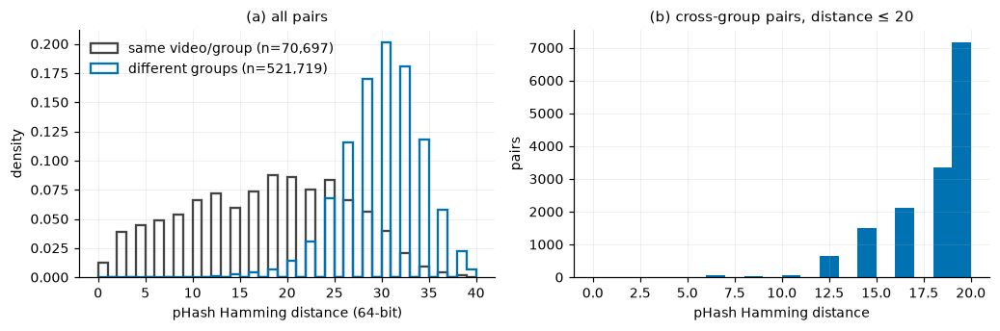

pairs sharing the same source stem: 145 | cross Roboflow split: 67
Hamming distance of same-stem pairs: {'count': 145.0, 'mean': 17.6, 'std': 6.8, 'min': 4.0, '25%': 12.0, '50%': 18.0, '75%': 22.0, 'max': 36.0}


In [8]:
# การกระจายของระยะ Hamming: คู่ภาพในกลุ่มเดียวกันเทียบกับต่างกลุ่ม
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))
bins = np.arange(0, 41)
for same, lab, col in [(True, "same video/group", "#444444"), (False, "different groups", "#0072B2")]:
    v = pair.loc[pair.same_group == same, "d"]
    ax[0].hist(v, bins=bins, density=True, histtype="step", lw=1.5, color=col, label=f"{lab} (n={len(v):,})")
ax[0].set_xlabel("pHash Hamming distance (64-bit)"); ax[0].set_ylabel("density"); ax[0].legend(frameon=False)
ax[0].set_title("(a) all pairs")
v = pair.loc[~pair.same_group, "d"]
ax[1].hist(v[v <= 20], bins=np.arange(0, 21), color="#0072B2")
ax[1].set_xlabel("pHash Hamming distance"); ax[1].set_ylabel("pairs")
ax[1].set_title("(b) cross-group pairs, distance ≤ 20")
fig.tight_layout(); savefig(fig, "fig01_phash_distance"); plt.show()

# คู่ภาพที่ชื่อต้นทางซ้ำ (stem เดียวกัน) — ตรวจว่าเป็นภาพเดียวกันหรือเฟรมต่างเวลา
same_stem = pair[pair.same_src_stem]
print(f"pairs sharing the same source stem: {len(same_stem)} | cross Roboflow split: {int(same_stem.cross_rf_split.sum())}")
print("Hamming distance of same-stem pairs:", same_stem.d.describe().round(1).to_dict())

saved figure: outputs/01_eda/df6d6fdc28/figures/fig02_closest_cross_group_pairs.png|pdf


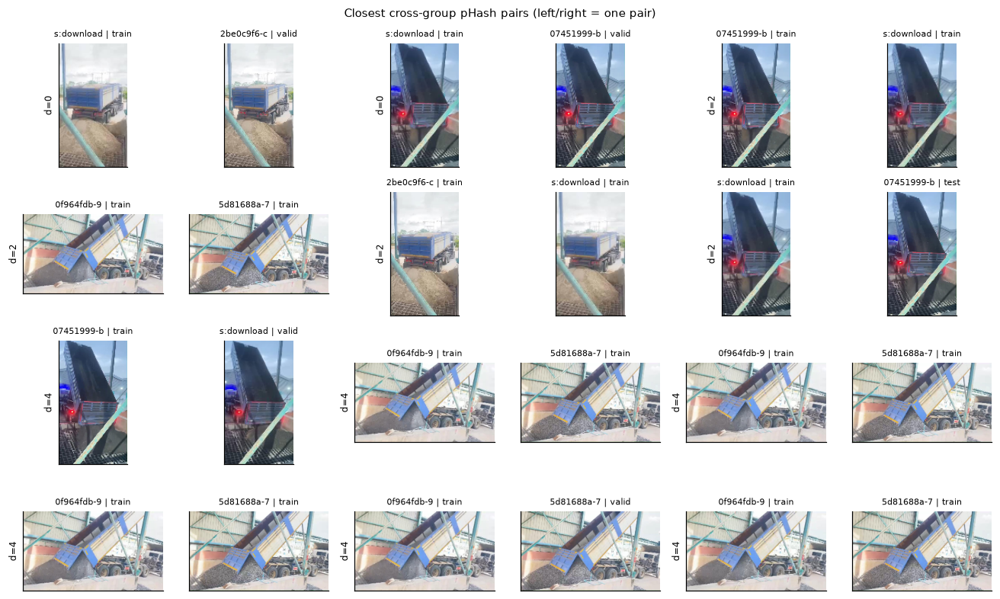

,i,j,d,same_group,same_src_stem,cross_rf_split,gi,gj
509109,680,810,0,False,False,True,s:download,2be0c9f6-c
509463,681,757,0,False,False,True,s:download,07451999-b
26492,24,681,2,False,False,False,07451999-b,s:download
146677,144,446,2,False,False,False,0f964fdb-9,5d81688a-7
211379,215,680,2,False,False,False,2be0c9f6-c,s:download
509690,681,984,2,False,False,True,s:download,07451999-b
25703,23,956,4,False,False,True,07451999-b,s:download
145733,143,446,4,False,False,False,0f964fdb-9,5d81688a-7
146676,144,445,4,False,False,False,0f964fdb-9,5d81688a-7
146678,144,447,4,False,False,False,0f964fdb-9,5d81688a-7


In [9]:
# คู่ภาพต่างกลุ่มที่ใกล้กันที่สุด 12 คู่ สำหรับตรวจด้วยตา
def thumb(path, h=150):
    im = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    return cv2.resize(im, (int(im.shape[1] * h / im.shape[0]), h))

closest = pair[~pair.same_group].nsmallest(12, "d")
fig, axes = plt.subplots(4, 6, figsize=(12, 7.5))
for k, (ax_pair, row) in enumerate(zip(axes.reshape(-1, 2), closest.itertuples())):
    for ax, idx in zip(ax_pair, (row.i, row.j)):
        ax.imshow(thumb(df_img.img_path[idx])); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(f"{df_img.group_short[idx]} | {df_img.rf_split[idx]}", fontsize=7)
    ax_pair[0].set_ylabel(f"d={row.d}", fontsize=8)
fig.suptitle("Closest cross-group pHash pairs (left/right = one pair)", fontsize=10)
fig.tight_layout(); savefig(fig, "fig02_closest_cross_group_pairs"); plt.show()
display(closest.assign(gi=df_img.group_short.values[closest.i], gj=df_img.group_short.values[closest.j]))

saved figure: outputs/01_eda/df6d6fdc28/figures/fig03_same_stem_pairs.png|pdf


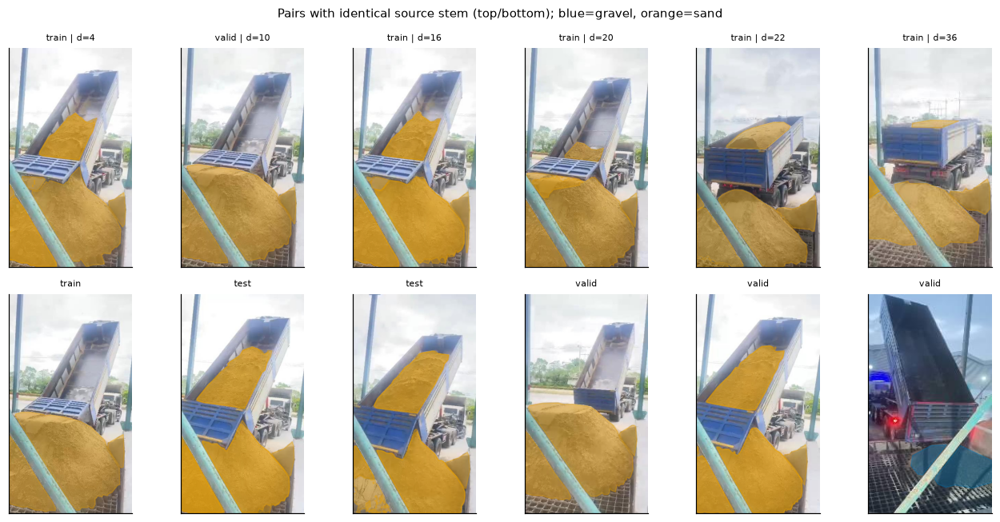

In [10]:
# คู่ภาพ stem เดียวกัน 6 คู่ แสดงพร้อม polygon เพื่อยืนยันว่าเป็นเฟรมต่างเวลา
def draw_polys(ax, image_id, lw=1.0, alpha=0.35, which=None):
    sub = (which if which is not None else df_inst)
    sub = sub[sub.image_id == image_id]
    for g in sub.itertuples():
        parts = list(g.geom.geoms) if hasattr(g.geom, "geoms") else [g.geom]
        for p in parts:
            if p.geom_type != "Polygon" or p.is_empty:
                continue
            xy = np.asarray(p.exterior.coords)
            ax.add_patch(MplPolygon(xy, closed=True, facecolor=CLASS_COLORS[g.cls_name], alpha=alpha,
                                    edgecolor=CLASS_COLORS[g.cls_name], lw=lw))

ex = same_stem.sort_values("d").iloc[np.linspace(0, len(same_stem) - 1, 6).astype(int)]
fig, axes = plt.subplots(2, 6, figsize=(12, 6))
for c, row in enumerate(ex.itertuples()):
    for rr, idx in enumerate((row.i, row.j)):
        ax = axes[rr, c]
        ax.imshow(cv2.cvtColor(cv2.imread(df_img.img_path[idx]), cv2.COLOR_BGR2RGB)); draw_polys(ax, idx)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(f"{df_img.rf_split[idx]} | d={row.d}" if rr == 0 else df_img.rf_split[idx], fontsize=7)
fig.suptitle("Pairs with identical source stem (top/bottom); blue=gravel, orange=sand", fontsize=10)
fig.tight_layout(); savefig(fig, "fig03_same_stem_pairs"); plt.show()

## 3.1 การรวมกลุ่มจากภาพเกือบซ้ำข้ามกลุ่ม

**Method** นับจำนวนคู่ภาพต่างกลุ่มที่มีระยะ pHash ไม่เกินเกณฑ์ต่าง ๆ (4–12) แยกตามคู่กลุ่ม แล้วเลือกเกณฑ์ `d_nd` ที่ชุดคู่กลุ่มคงที่ (ไม่มีคู่กลุ่มใหม่เพิ่ม) จากนั้นตรวจทุกคู่กลุ่มที่ผ่านเกณฑ์ด้วยตา และรวมกลุ่มด้วย union-find

**Rationale** ผลในหัวข้อ 3 แสดงว่ามีคู่ภาพต่างกลุ่มที่ระยะ 0–4 ซึ่งในรูปที่ 2 เป็นเหตุการณ์เดียวกันที่บันทึกเป็นวิดีโอคนละไฟล์ (ต่างความละเอียด) หรือเป็นภาพนิ่งที่ตัดมาจากวิดีโอ ถ้าไม่รวมกลุ่ม การแบ่งตามกลุ่มจะยังรั่วไหล

**Reference** Barz & Denzler (2020); Kapoor & Narayanan (2023)

**Implementation** เกณฑ์ที่เลือกบันทึกใน `D_ND` เหตุผลของค่าที่เลือกอยู่ในผลของ cell ถัดไป การรวมใช้กฎสองแบบ: คู่วิดีโอกับวิดีโอรวมด้วย union-find ส่วนภาพนิ่งผูกกับกลุ่มวิดีโอที่ใกล้ที่สุดเพียงกลุ่มเดียว เหตุผลคือในการรันครั้งแรก union-find รวมวิดีโอ 07451999 (gravel) เข้ากับ 2be0c9f6 (sand) ผ่านภาพนิ่ง "download" สองภาพที่ใกล้กับวิดีโอคนละตัว ซึ่งเป็นการรวมที่ไม่มีหลักฐานว่าวิดีโอทั้งสองเป็นเหตุการณ์เดียวกัน

**Limitation** เกณฑ์ที่สูงขึ้นเริ่มจับคู่ภาพจากเหตุการณ์ต่างกันที่ถ่ายจากจุดติดตั้งกล้องเดียวกัน (ฉากหลังเหมือนกันแต่วัสดุต่างกัน) การรวมกลุ่มเหล่านั้นจะทำให้กลุ่มใหญ่เกินจำเป็น จึงไม่รวม

In [11]:
thr_rows = []
for thr in (4, 6, 8, 10, 12):
    sub = pair[(~pair.same_group) & (pair.d <= thr)]
    gp = pd.Series([tuple(sorted((grp[a][:8], grp[b][:8]))) for a, b in zip(sub.i, sub.j)]).value_counts()
    for (ga, gb), n in gp.items():
        thr_rows.append(dict(threshold=thr, group_a=ga, group_b=gb, pairs=int(n)))
df_thr = pd.DataFrame(thr_rows)
pivot_thr = df_thr.pivot_table(index=["group_a", "group_b"], columns="threshold", values="pairs", fill_value=0)
save_table(pivot_thr.reset_index(), "near_duplicate_group_pairs_by_threshold")
display(pivot_thr)

saved table: outputs/01_eda/df6d6fdc28/tables/near_duplicate_group_pairs_by_threshold.csv  (10 rows)


threshold           4     6     8     10     12
group_a  group_b                               
07451999 8f435cb5  0.0   0.0   0.0   0.0    2.0
         still_do  4.0   6.0   7.0  10.0   13.0
0f964fdb 5d81688a  6.0  21.0  48.0  96.0  185.0
2be0c9f6 fa45e6fb  0.0   0.0   0.0   4.0  505.0
         still_do  6.0  16.0  20.0  22.0   27.0
5079fbab b029e315  0.0   0.0   0.0   0.0    1.0
6f40fbbd fa45e6fb  0.0   0.0   0.0   0.0    3.0
8f435cb5 b029e315  1.0  23.0  37.0  55.0   86.0
96ecd4fe d56fcb3c  0.0   0.0   0.0   0.0    2.0
e9eebbd1 f9b12ec3  0.0   0.0   0.0   0.0    1.0

group pairs with ≥1 cross-group pair at d ≤ 8:


threshold,group_a,group_b,8
0,07451999,still_do,7.0
1,0f964fdb,5d81688a,48.0
2,2be0c9f6,still_do,20.0
3,8f435cb5,b029e315,37.0


saved figure: outputs/01_eda/df6d6fdc28/figures/fig09_group_merge_candidates.png|pdf


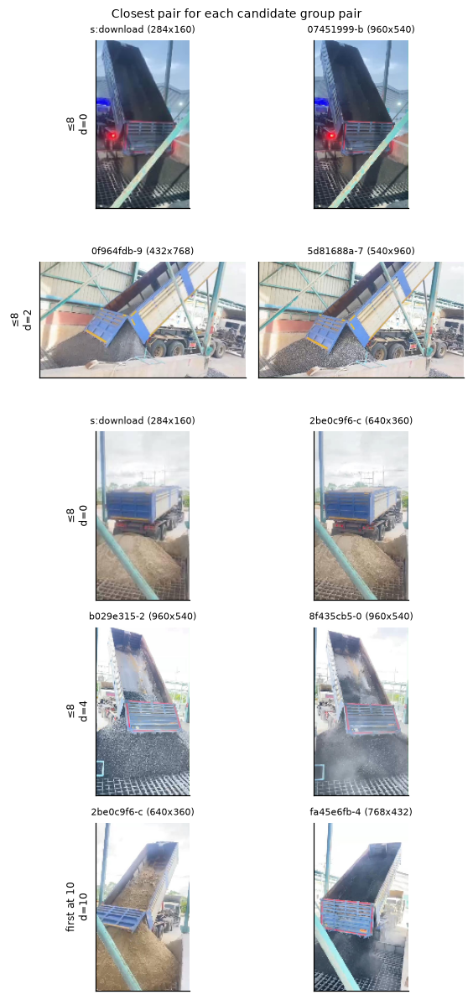

In [12]:
# เกณฑ์ที่เลือก: ชุดคู่กลุ่มเหมือนกันทุกเกณฑ์ตั้งแต่ 4 ถึง 8 และเริ่มมีคู่กลุ่มใหม่ที่เกณฑ์ 10
D_ND = 8
CONFIG["near_dup_threshold"] = D_ND
cand = pivot_thr[pivot_thr[D_ND] > 0].reset_index()[["group_a", "group_b", D_ND]]
print(f"group pairs with ≥1 cross-group pair at d ≤ {D_ND}:"); display(cand)

# แสดงคู่ภาพที่ใกล้ที่สุดของทุกคู่กลุ่ม (ตรวจด้วยตา) และคู่กลุ่มแรกที่ปรากฏที่เกณฑ์ 10 เพื่อเปรียบเทียบ
extra = pivot_thr[(pivot_thr[D_ND] == 0) & (pivot_thr[10] > 0)].reset_index()[["group_a", "group_b"]]
show_pairs = pd.concat([cand[["group_a", "group_b"]].assign(kind=f"≤{D_ND}"), extra.assign(kind="first at 10")])
short = np.array([g[:8] for g in grp])
fig, axes = plt.subplots(len(show_pairs), 2, figsize=(5.2, 2.2 * len(show_pairs)))
for r, row in enumerate(show_pairs.itertuples()):
    m = pair[(~pair.same_group) & (((short[pair.i] == row.group_a) & (short[pair.j] == row.group_b)) |
                                   ((short[pair.i] == row.group_b) & (short[pair.j] == row.group_a)))].nsmallest(1, "d").iloc[0]
    for c, idx in enumerate((m.i, m.j)):
        ax = axes[r, c]; ax.imshow(thumb(df_img.img_path[idx], 180)); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(f"{df_img.group_short[idx]} ({df_img.height[idx]}x{df_img.width[idx]})", fontsize=7)
    axes[r, 0].set_ylabel(f"{row.kind}\nd={m.d}", fontsize=8)
fig.suptitle("Closest pair for each candidate group pair", fontsize=9)
fig.tight_layout(); savefig(fig, "fig09_group_merge_candidates"); plt.show()

In [13]:
# การรวมกลุ่ม: (1) วิดีโอกับวิดีโอ ใช้ union-find ตามคู่ภาพเกือบซ้ำ d <= D_ND
#              (2) ภาพนิ่ง ผูกกับกลุ่มวิดีโอที่ใกล้ที่สุดเพียงกลุ่มเดียว (ไม่ใช้เป็นสะพานเชื่อมวิดีโอสองกลุ่ม)
is_vid = df_img.is_video.values
parent = {g: g for g in df_img.group.unique()}
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        na, nb = (df_img.group == ra).sum(), (df_img.group == rb).sum()
        parent[rb if na >= nb else ra] = ra if na >= nb else rb
nd = pair[(~pair.same_group) & (pair.d <= D_ND)]
vv = nd[is_vid[nd.i.values] & is_vid[nd.j.values]]
for a, b in zip(vv.i, vv.j):
    union(grp[a], grp[b])
still_links = []
vid_idx = np.where(is_vid)[0]
for g in df_img.loc[~df_img.is_video, "group"].unique():
    idx = np.where(grp == g)[0]
    dmin = D[np.ix_(idx, vid_idx)]
    k = np.unravel_index(np.argmin(dmin), dmin.shape)
    if dmin[k] <= D_ND:
        target = find(grp[vid_idx[k[1]]])
        parent[find(g)] = target
        still_links.append(dict(still_group=g[:20], linked_video_group=target[:13], min_distance=int(dmin[k])))
df_img["group_merged"] = df_img.group.map(find)
merge_tab = (df_img[df_img.group != df_img.group_merged].groupby(["group", "group_merged"]).size()
             .rename("images").reset_index())
merge_tab["group"] = merge_tab.group.str[:13]; merge_tab["group_merged"] = merge_tab.group_merged.str[:13]
save_table(merge_tab, "group_merges")
print(f"groups before: {df_img.group.nunique()} -> after merge: {df_img.group_merged.nunique()}")
display(merge_tab); display(pd.DataFrame(still_links))

saved table: outputs/01_eda/df6d6fdc28/tables/group_merges.csv  (5 rows)
groups before: 32 -> after merge: 27


,group,group_merged,images
0,5d81688a-7f52,0f964fdb-9fc1,21
1,8f435cb5-02c7,b029e315-2e53,28
2,still_downloa,2be0c9f6-caf7,1
3,still_downloa,07451999-bdf8,1
4,still_downloa,07451999-bdf8,1


,still_group,linked_video_group,min_distance
0,still_download_680,2be0c9f6-caf7,0
1,still_download_681,07451999-bdf8,0
2,still_download_956,07451999-bdf8,4


## 4. สถิติของภาพ: ความสว่าง contrast สี และความคมชัด

**Method** คำนวณต่อภาพ ได้แก่ ค่าเฉลี่ยและส่วนเบี่ยงเบนของ L\* ในปริภูมิ CIELAB (ความสว่างและ RMS contrast) ค่าเฉลี่ยของ a\* และ b\* (การเอนของสี) ความอิ่มตัวเฉลี่ยใน HSV ดัชนี colourfulness ความแปรปรวนของ Laplacian (ความคมชัด) และสัดส่วนพิกเซลที่มืดหรือสว่างจนตัดปลาย

**Rationale** สถิติเหล่านี้ใช้อธิบายความแปรปรวนของแสงและการถ่ายภาพระหว่างแหล่งข้อมูล ใช้เลือกภาพตัวอย่างใน Notebook 02 และใช้วัด distribution shift ใน Notebook 04

**Reference** ปริภูมิสี CIELAB (CIE 15:2004); ดัชนี colourfulness M3 ของ Hasler & Süsstrunk (2003), *Proc. SPIE* 5007: 87–95 (ผลรวมเชิงเส้นของค่าเฉลี่ยและส่วนเบี่ยงเบนมาตรฐานใน opponent colour space); ความแปรปรวนของผลตอบสนอง Laplacian ใช้เป็นตัวชี้วัดความคมชัด (focus measure) เพราะ Laplacian ตอบสนองต่อการเปลี่ยนแปลงความเข้มแบบเฉียบพลัน ภาพที่เบลอจึงมีค่าความแปรปรวนต่ำ

**Implementation** ย่อภาพให้ด้านสั้นเท่ากับ 360 พิกเซลก่อนคำนวณความแปรปรวนของ Laplacian เพราะค่านี้ขึ้นกับความละเอียดของภาพ ถ้าไม่ย่อจะเปรียบเทียบข้ามแหล่งที่มาที่ความละเอียดต่างกันไม่ได้

**Limitation** ภาพผ่านการบีบอัด JPEG และไม่มีข้อมูล exposure หรือ white balance ของกล้อง ค่าเหล่านี้จึงสะท้อนภาพที่บันทึกแล้ว ไม่ใช่ความสว่างจริงของฉาก

In [14]:
def image_stats(path, short=CONFIG["lap_short_side"]):
    bgr = cv2.imread(path)
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
    L = lab[..., 0] * 100 / 255; a = lab[..., 1] - 128; b = lab[..., 2] - 128
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    rgb = bgr[..., ::-1].astype(np.float32)
    rg = rgb[..., 0] - rgb[..., 1]; yb = 0.5 * (rgb[..., 0] + rgb[..., 1]) - rgb[..., 2]
    colorfulness = np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean())
    g = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    s = short / min(g.shape)
    gs = cv2.resize(g, (round(g.shape[1] * s), round(g.shape[0] * s)), interpolation=cv2.INTER_AREA)
    return dict(L_mean=L.mean(), L_std=L.std(), a_mean=a.mean(), b_mean=b.mean(),
                sat_mean=hsv[..., 1].mean() / 255, colorfulness=colorfulness,
                lap_var=cv2.Laplacian(gs, cv2.CV_64F).var(),
                dark_frac=(g < 10).mean(), bright_frac=(g > 245).mean())

t0 = time.time()
stats = pd.DataFrame([image_stats(p) for p in df_img.img_path])
df_img = pd.concat([df_img.drop(columns=[c for c in stats.columns if c in df_img], errors="ignore"), stats], axis=1)
print(f"computed in {time.time()-t0:.1f}s")
save_table(df_img[["file", "group", "rf_split", "width", "height"] + list(stats.columns)], "image_stats")
df_img[list(stats.columns)].describe().round(3)

computed in 6.5s
saved table: outputs/01_eda/df6d6fdc28/tables/image_stats.csv  (1089 rows)


,L_mean,L_std,a_mean,b_mean,sat_mean,colorfulness,lap_var,dark_frac,bright_frac
count,1089.000,1089.000,1089.000,1089.000,1089.000,1089.000,1089.000,1089.000,1089.000
mean,67.200,21.046,0.386,-0.602,0.150,28.885,776.667,0.000,0.107
std,7.549,2.930,0.999,4.248,0.047,5.647,485.022,0.001,0.083
min,45.032,13.949,-5.448,-13.091,0.069,13.758,104.666,0.000,0.000
25%,66.734,19.122,-0.278,-2.940,0.118,25.557,459.211,0.000,0.028
50%,70.373,20.268,0.478,0.158,0.144,28.581,658.699,0.000,0.100
75%,71.828,23.043,0.932,2.853,0.161,31.538,919.916,0.000,0.176
max,75.392,30.286,5.166,6.646,0.307,55.153,4574.076,0.010,0.297


/tmp/ipykernel_1337487/1726167966.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, widths=0.6, showfliers=False, patch_artist=True)
/tmp/ipykernel_1337487/1726167966.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, widths=0.6, showfliers=False, patch_artist=True)
/tmp/ipykernel_1337487/1726167966.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, widths=0.6, showfliers=False, patch_artist=True)
/tmp/ipykernel_1337487/1726167966.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use or

saved figure: outputs/01_eda/df6d6fdc28/figures/fig04_image_stats_per_group.png|pdf


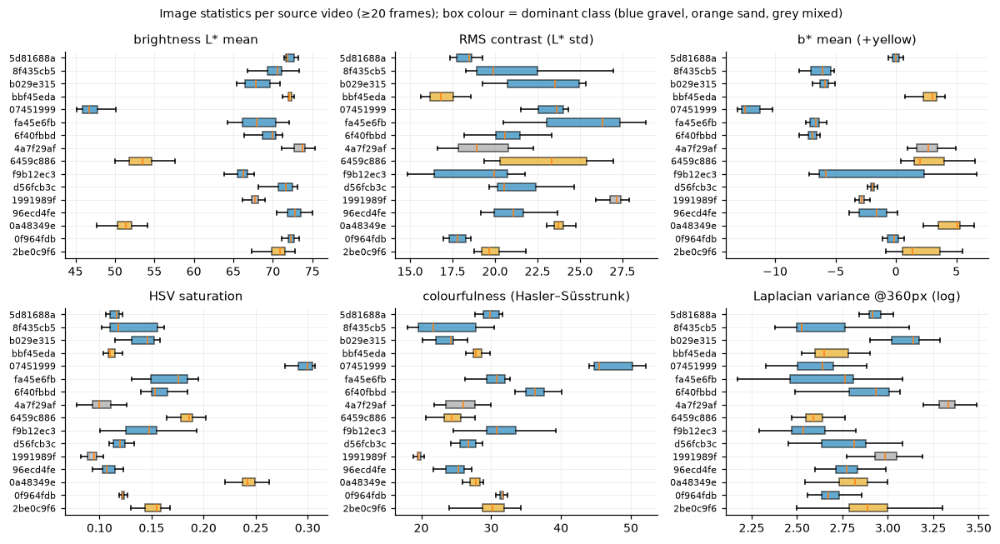

In [15]:
# ป้ายสถานะระดับภาพจาก bronze (ใช้อธิบายข้อมูลเบื้องต้น; ป้ายที่ใช้จริงคำนวณจาก Silver ในหัวข้อ 8)
cls_per_img = df_inst.groupby(["image_id", "cls_name"]).area_frac.sum().unstack(fill_value=0).reindex(df_img.image_id, fill_value=0)
def state_of(g, s, thr=0.0):
    return "mixed" if (g > thr and s > thr) else "gravel" if g > thr else "sand" if s > thr else "none"
df_img["state_bronze"] = [state_of(g, s) for g, s in zip(cls_per_img.get("gravel", 0), cls_per_img.get("sand", 0))]

stat_cols = ["L_mean", "L_std", "b_mean", "sat_mean", "colorfulness", "lap_var"]
labels = {"L_mean": "brightness L* mean", "L_std": "RMS contrast (L* std)", "b_mean": "b* mean (+yellow)",
          "sat_mean": "HSV saturation", "colorfulness": "colourfulness (Hasler–Süsstrunk)",
          "lap_var": "Laplacian variance @360px (log)"}
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
order = df_img.groupby("group").size().sort_values(ascending=False)
top = order[order >= 20].index
for ax, c in zip(axes.ravel(), stat_cols):
    data = [np.log10(df_img.loc[df_img.group == g, c]) if c == "lap_var" else df_img.loc[df_img.group == g, c] for g in top]
    bp = ax.boxplot(data, vert=False, widths=0.6, showfliers=False, patch_artist=True)
    for patch, g in zip(bp["boxes"], top):
        st = df_img.loc[df_img.group == g, "state_bronze"].mode()[0]
        patch.set_facecolor(CLASS_COLORS.get(st, "#999999")); patch.set_alpha(0.6)
    ax.set_yticks(range(1, len(top) + 1), [g[:8] for g in top], fontsize=7)
    ax.set_title(labels[c])
fig.suptitle("Image statistics per source video (≥20 frames); box colour = dominant class (blue gravel, orange sand, grey mixed)", fontsize=9)
fig.tight_layout(); savefig(fig, "fig04_image_stats_per_group"); plt.show()

## 5. สถิติของ annotation และการกระจายของคลาส

**Method** สรุปจำนวน instance ต่อภาพ การกระจายของพื้นที่ instance (สัดส่วนของพื้นที่ภาพ) อัตราส่วนด้านของ minimum rotated rectangle ความครอบคลุมของ mask ต่อภาพ (สัดส่วนของพื้นที่ภาพที่มี annotation) และขนาดตามเกณฑ์ small/medium/large ของ COCO

**Rationale** การกระจายของขนาดเป็นข้อมูลหลักสำหรับกำหนดเกณฑ์ instance เล็กของ Silver (หัวข้อ 7) และใช้ประเมินว่าการปรับปรุงสำหรับวัตถุเล็ก เช่น SAHI หรือ P2 head มีเหตุผลรองรับหรือไม่

**Reference** COCO detection evaluation: small < 32², medium 32²–96², large > 96² พิกเซล (Lin et al., 2014, ECCV; ค่านี้ตรงกับ `areaRng` ใน `pycocotools/cocoeval.py` ที่ติดตั้ง)

**Implementation** คำนวณพื้นที่ COCO ที่ความละเอียดอินพุตของแบบจำลอง (ด้านยาว 640 พิกเซล หลัง letterbox) เพราะเป็นความละเอียดที่แบบจำลองเห็นจริง

**Limitation** ภาพต้นฉบับมีหลายความละเอียด ขนาดในหน่วยพิกเซลของภาพต้นฉบับจึงเปรียบเทียบข้ามแหล่งไม่ได้โดยตรง

saved figure: outputs/01_eda/df6d6fdc28/figures/fig05_annotation_statistics.png|pdf


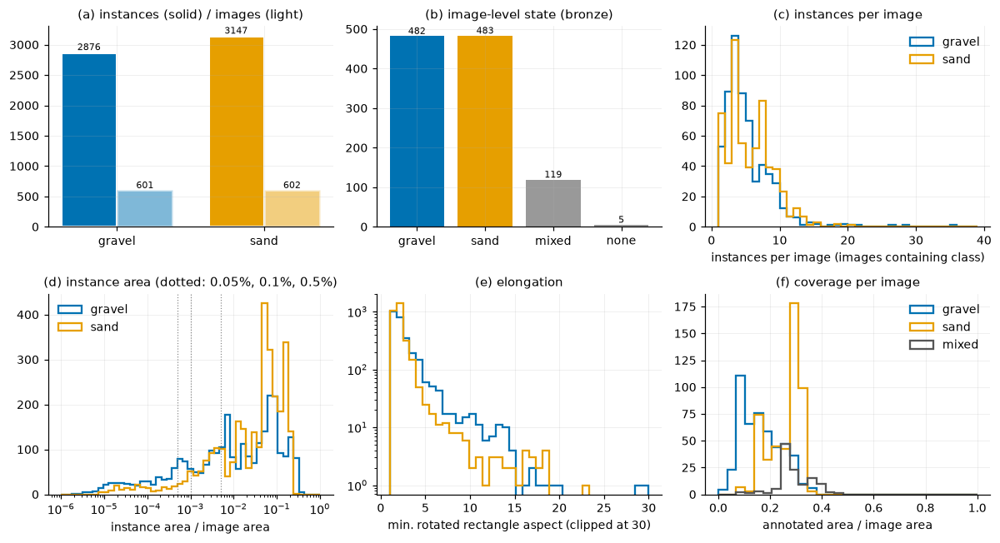

,instances,images containing
gravel,2876,601
sand,3147,602


In [16]:
union_cov = []
for iid, sub in df_inst.groupby("image_id"):
    u = shapely.union_all(list(sub.geom.values))
    r = df_img.loc[iid]
    union_cov.append((iid, u.area / (r.width * r.height)))
cov = pd.Series(dict(union_cov)).reindex(df_img.image_id, fill_value=0.0)
df_img["coverage_bronze"] = cov.values

fig, axes = plt.subplots(2, 3, figsize=(11, 6))
# (a) จำนวนภาพและ instance ต่อคลาส
cnt = pd.DataFrame({"instances": df_inst.cls_name.value_counts(),
                    "images containing": pd.Series({c: int((cls_per_img[c] > 0).sum()) for c in CLASS_NAMES})}).loc[CLASS_NAMES]
x = np.arange(2); w = 0.38
for k, col in enumerate(cnt.columns):
    bars = axes[0, 0].bar(x + (k - 0.5) * w, cnt[col], w, color=[CLASS_COLORS[c] for c in CLASS_NAMES],
                          alpha=1.0 if k == 0 else 0.5, edgecolor="white", lw=2)
    axes[0, 0].bar_label(bars, fmt="%d", fontsize=7)
axes[0, 0].set_xticks(x, CLASS_NAMES); axes[0, 0].set_title("(a) instances (solid) / images (light)")
# (b) สถานะระดับภาพ
st = df_img.state_bronze.value_counts().reindex(["gravel", "sand", "mixed", "none"], fill_value=0)
bars = axes[0, 1].bar(st.index, st.values, color=[CLASS_COLORS.get(s, "#999999") for s in st.index])
axes[0, 1].bar_label(bars, fontsize=7); axes[0, 1].set_title("(b) image-level state (bronze)")
# (c) instance ต่อภาพ
for c in CLASS_NAMES:
    v = df_inst[df_inst.cls_name == c].groupby("image_id").size()
    axes[0, 2].hist(v, bins=np.arange(1, 40), histtype="step", lw=1.5, color=CLASS_COLORS[c], label=c)
axes[0, 2].set_xlabel("instances per image (images containing class)"); axes[0, 2].legend(frameon=False)
axes[0, 2].set_title("(c) instances per image")
# (d) พื้นที่ instance (log)
bins = np.logspace(-6, 0, 50)
for c in CLASS_NAMES:
    axes[1, 0].hist(df_inst.loc[df_inst.cls_name == c, "area_frac"], bins=bins, histtype="step", lw=1.5,
                    color=CLASS_COLORS[c], label=c)
for t in (0.0005, 0.001, 0.005):
    axes[1, 0].axvline(t, color="#888888", ls=":", lw=0.8)
axes[1, 0].set_xscale("log"); axes[1, 0].set_xlabel("instance area / image area"); axes[1, 0].legend(frameon=False)
axes[1, 0].set_title("(d) instance area (dotted: 0.05%, 0.1%, 0.5%)")
# (e) อัตราส่วนด้าน
for c in CLASS_NAMES:
    axes[1, 1].hist(np.clip(df_inst.loc[df_inst.cls_name == c, "mrr_aspect"], 1, 30), bins=np.linspace(1, 30, 40),
                    histtype="step", lw=1.5, color=CLASS_COLORS[c], label=c)
axes[1, 1].set_yscale("log"); axes[1, 1].set_xlabel("min. rotated rectangle aspect (clipped at 30)")
axes[1, 1].set_title("(e) elongation")
# (f) ความครอบคลุมต่อภาพ
for s in ["gravel", "sand", "mixed"]:
    axes[1, 2].hist(df_img.loc[df_img.state_bronze == s, "coverage_bronze"], bins=np.linspace(0, 1, 30), histtype="step",
                    lw=1.5, color=CLASS_COLORS.get(s, "#555555"), label=s)
axes[1, 2].set_xlabel("annotated area / image area"); axes[1, 2].legend(frameon=False); axes[1, 2].set_title("(f) coverage per image")
fig.tight_layout(); savefig(fig, "fig05_annotation_statistics"); plt.show()
display(cnt)

overlapping pairs: 2086 | same class 2086 | cross class 0
             count   mean    std  min    50%  90%  max
same_class                                            
True        2086.0  0.809  0.369  0.0  0.994  1.0  1.0
saved figure: outputs/01_eda/df6d6fdc28/figures/fig06_instance_overlap.png|pdf


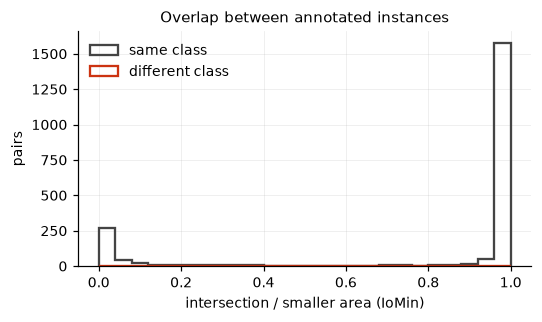

saved table: outputs/01_eda/df6d6fdc28/tables/instance_overlaps.csv  (2086 rows)


In [17]:
# instance ที่ซ้อนทับกัน: คลาสเดียวกัน (อาจเป็นการ annotate ซ้ำ) และต่างคลาส (ความกำกวม)
ov_rows = []
for iid, sub in df_inst.groupby("image_id"):
    geoms = list(sub.geom.values); ids = sub.inst_id.values; cls = sub.cls.values
    tree = STRtree(geoms)
    for a, b in zip(*tree.query(geoms, predicate="intersects")):
        if a >= b:
            continue
        inter = geoms[a].intersection(geoms[b]).area
        if inter <= 0:
            continue
        ov_rows.append(dict(image_id=iid, inst_a=ids[a], inst_b=ids[b], same_class=cls[a] == cls[b],
                            iomin=inter / min(geoms[a].area, geoms[b].area),
                            iou=inter / geoms[a].union(geoms[b]).area))
df_ov = pd.DataFrame(ov_rows)
print(f"overlapping pairs: {len(df_ov)} | same class {int(df_ov.same_class.sum())} | cross class {int((~df_ov.same_class).sum())}")
print(df_ov.groupby("same_class").iomin.describe(percentiles=[.5, .9]).round(3))
fig, ax = plt.subplots(figsize=(5, 3))
for same, col, lab in [(True, "#444444", "same class"), (False, "#CC3311", "different class")]:
    ax.hist(df_ov.loc[df_ov.same_class == same, "iomin"], bins=np.linspace(0, 1, 26), histtype="step", lw=1.5, color=col, label=lab)
ax.set_xlabel("intersection / smaller area (IoMin)"); ax.set_ylabel("pairs"); ax.legend(frameon=False)
ax.set_title("Overlap between annotated instances")
fig.tight_layout(); savefig(fig, "fig06_instance_overlap"); plt.show()
save_table(df_ov, "instance_overlaps")

## 6. ตัวแปรกวนระหว่างคลาส แหล่งที่มา และความละเอียดภาพ

**Method** ตารางไขว้ระหว่างกลุ่ม (วิดีโอ) กับสถานะระดับภาพ และระหว่างความละเอียดภาพกับสถานะ แล้ววัดความสัมพันธ์ด้วย Cramér's V

**Rationale** ถ้าคลาสสัมพันธ์กับแหล่งที่มาหรือความละเอียดภาพอย่างมาก แบบจำลองอาจใช้ลักษณะของฉากหรือความละเอียดแทนเนื้อวัสดุในการตัดสินใจ (shortcut learning) ผลบนชุดทดสอบที่มาจากฉากเดียวกับชุดฝึกจะปกปิดปัญหานี้ไว้

**Reference** Geirhos et al. (2020), "Shortcut learning in deep neural networks", *Nature Machine Intelligence* 2(11): 665–673 — นิยาม shortcut ว่าเป็นกฎการตัดสินใจที่ทำงานได้ดีบน benchmark มาตรฐานแต่ไม่ถ่ายโอนไปสู่เงื่อนไขการทดสอบที่ยากกว่า; Cramér's V เป็นการวัดความสัมพันธ์ของตัวแปรเชิงกลุ่มจาก χ²

**Implementation** `scipy.stats.chi2_contingency` แล้วคำนวณ V = √(χ² / (n·(min(r,c)−1)))

**Limitation** Cramér's V แสดงความสัมพันธ์ ไม่ได้พิสูจน์ว่าแบบจำลองใช้ทางลัดนั้นจริง ข้อสรุปเชิงเหตุต้องดูจากผลบนกลุ่มที่ไม่เคยเห็นใน Notebook 03 และ 04

In [18]:
from scipy.stats import chi2_contingency
def cramers_v(tab):
    chi2 = chi2_contingency(tab, correction=False)[0]
    n = tab.values.sum(); r, c = tab.shape
    return float(np.sqrt(chi2 / (n * (min(r, c) - 1))))

df_img["res_bucket"] = (df_img.height.astype(str) + "x" + df_img.width.astype(str))
vid = df_img[df_img.state_bronze != "none"]
ct_group = pd.crosstab(vid.group.str[:8], vid.state_bronze)
ct_res = pd.crosstab(vid.res_bucket, vid.state_bronze)
cv_tab = pd.DataFrame([dict(variable="source group", cramers_v=cramers_v(ct_group), levels=ct_group.shape[0]),
                       dict(variable="resolution", cramers_v=cramers_v(ct_res), levels=ct_res.shape[0])])
save_table(cv_tab, "confounding_cramers_v"); save_table(ct_group.reset_index(), "crosstab_group_state")
display(cv_tab)

g_tab = (df_img.groupby("group").agg(images=("file", "size"), video=("is_video", "first"),
                                      res=("res_bucket", lambda s: s.mode()[0]),
                                      rf_splits=("rf_split", lambda s: "/".join(f"{k[0]}{v}" for k, v in s.value_counts().items())),
                                      gravel_imgs=("state_bronze", lambda s: int(s.isin(["gravel", "mixed"]).sum())),
                                      sand_imgs=("state_bronze", lambda s: int(s.isin(["sand", "mixed"]).sum())),
                                      L_mean=("L_mean", "mean"))
         .sort_values("images", ascending=False))
g_inst = df_inst.groupby(["group", "cls_name"]).size().unstack(fill_value=0)
g_tab = g_tab.join(g_inst.add_prefix("inst_")).fillna(0)
save_table(g_tab.reset_index(), "groups_bronze")
g_tab.head(20)

saved table: outputs/01_eda/df6d6fdc28/tables/confounding_cramers_v.csv  (2 rows)
saved table: outputs/01_eda/df6d6fdc28/tables/crosstab_group_state.csv  (30 rows)


,variable,cramers_v,levels
0,source group,0.980904,30
1,resolution,0.628376,10


saved table: outputs/01_eda/df6d6fdc28/tables/groups_bronze.csv  (32 rows)


,images,video,res,rf_splits,gravel_imgs,sand_imgs,L_mean,inst_gravel,inst_sand
group,,,,,,,,,
2be0c9f6-caf7-4f26-9b59-b1299865a721,315,True,640x360,t215/v68/t32,0,314,70.471977,0,2160
0f964fdb-9fc1-4941-9c12-15445855221a,90,True,432x768,t62/v18/t10,90,0,72.347504,366,0
0a48349e-f671-436a-8af5-de54f079109f,81,True,640x360,t57/v16/t8,0,81,51.231651,0,419
96ecd4fe-5910-4cd4-8a24-11ed20aab3b7,66,True,640x360,t46/v14/t6,62,0,72.726280,183,0
1991989f-1bf5-4e50-89bb-7301b220ac01,65,True,768x432,t43/v14/t8,65,64,67.736359,480,68
d56fcb3c-0531-4696-8b67-2645d89e4a7f,57,True,768x432,t39/v12/t6,57,0,71.113770,266,0
f9b12ec3-0036-45f7-8cc3-4d2e6f481cdc,56,True,960x540,t38/v12/t6,56,0,65.867943,217,0
6459c886-45a3-4065-82bc-2ed15b2875b0,49,True,640x360,t36/v9/t4,0,49,53.337009,0,200
4a7f29af-8d1c-4a3b-90e6-b9cf771fd1c2,48,True,960x540,t34/v11/t3,48,48,73.243507,69,115


## 7. ตัวอย่างภาพและกรณียาก

**Method** แสดงภาพตัวแทนของแต่ละวิดีโอหลัก (เฟรมกลางของวิดีโอ) พร้อม polygon และแสดงกรณียากสี่ประเภทที่เลือกด้วยเกณฑ์ที่กำหนดไว้ ได้แก่ ภาพที่มี instance เล็กมากที่สุด ภาพที่มี instance ต่างคลาสซ้อนทับกัน ภาพที่มืดที่สุด และภาพที่คมชัดน้อยที่สุด

**Rationale** การตรวจด้วยตาช่วยยืนยันข้อสรุปจากสถิติ และระบุลักษณะที่ตัวเลขสรุปไม่ได้ เช่น ขอบเขตกองวัสดุที่กำกวม หรือวัสดุที่กระจายบนตะแกรง

**Implementation** การเลือกภาพใช้เกณฑ์เชิงตัวเลขที่บันทึกใน cell ไม่ได้เลือกด้วยมือ

**Limitation** ตัวอย่างจำนวนน้อยไม่ได้แทนทั้งชุดข้อมูล และใช้เพื่ออธิบายเท่านั้น

saved figure: outputs/01_eda/df6d6fdc28/figures/fig07_representative_per_video.png|pdf


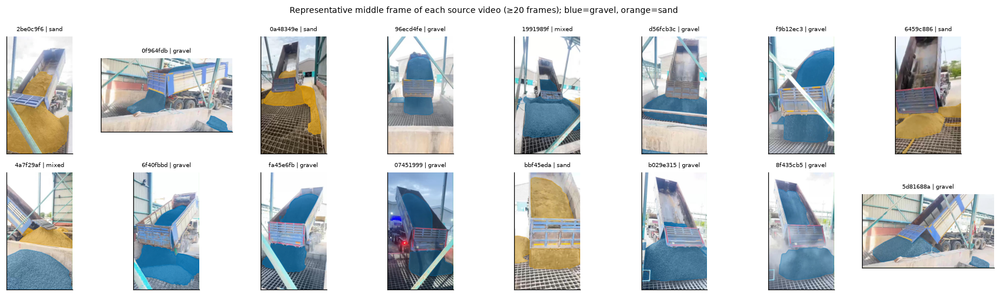

In [19]:
def show_grid(ids, ncol, title, name, sub_titles=None, which=None, h=2.3):
    nrow = int(np.ceil(len(ids) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * 2.0, nrow * h))
    for k, ax in enumerate(np.atleast_1d(axes).ravel()):
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if k >= len(ids):
            ax.axis("off"); continue
        iid = ids[k]
        ax.imshow(cv2.cvtColor(cv2.imread(df_img.img_path[iid]), cv2.COLOR_BGR2RGB)); draw_polys(ax, iid, which=which)
        ax.set_title(sub_titles[k] if sub_titles else df_img.group_short[iid], fontsize=6.5)
    fig.suptitle(title, fontsize=9); fig.tight_layout(); savefig(fig, name); plt.show()

reps = []
for g in g_tab[g_tab.images >= 20].index:
    sub = df_img[df_img.group == g].sort_values("frame")
    reps.append(sub.image_id.iloc[len(sub) // 2])
show_grid(reps, 8, "Representative middle frame of each source video (≥20 frames); blue=gravel, orange=sand",
          "fig07_representative_per_video",
          [f"{df_img.group_short[i][:8]} | {df_img.state_bronze[i]}" for i in reps])

saved figure: outputs/01_eda/df6d6fdc28/figures/fig08_difficult_samples.png|pdf


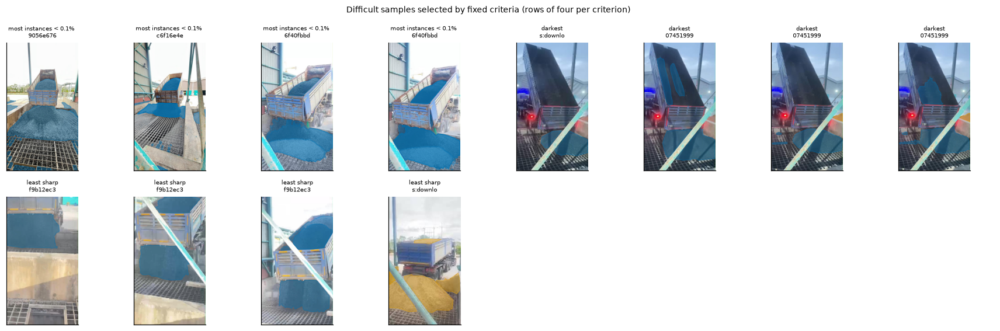

saved table: outputs/01_eda/df6d6fdc28/tables/difficult_samples.csv  (12 rows)


In [20]:
small_cnt = df_inst[df_inst.area_frac < 0.001].groupby("image_id").size()
cross_ov = df_ov[~df_ov.same_class].groupby("image_id").iomin.max()
hard = {
    "most instances < 0.1% area": small_cnt.nlargest(4).index.tolist(),
    "largest cross-class overlap": cross_ov.nlargest(4).index.tolist(),
    "darkest (L* mean)": df_img.nsmallest(4, "L_mean").image_id.tolist(),
    "least sharp (Laplacian var.)": df_img.nsmallest(4, "lap_var").image_id.tolist(),
}
ids = sum(hard.values(), [])
titles = [f"{k.split(' (')[0][:22]}\n{df_img.group_short[i][:8]}" for k, v in hard.items() for i in v]
show_grid(ids, 8, "Difficult samples selected by fixed criteria (rows of four per criterion)", "fig08_difficult_samples", titles, h=2.6)
save_table(pd.DataFrame([dict(criterion=k, image=df_img.file[i]) for k, v in hard.items() for i in v]), "difficult_samples")

## 8. การวิเคราะห์ความไวของกฎ Silver ต่อค่า threshold

**Method** กฎทำความสะอาดมีสี่ขั้นตามลำดับ (`RESEARCH_PLAN.md` หัวข้อ 6.2)

1. ซ่อม geometry ด้วย `make_valid` และเก็บชิ้นส่วนหลักเมื่อ polygon แตกเป็นหลายชิ้น
2. opening เชิงสัณฐาน `buffer(-ε)·buffer(+ε)` เพื่อตัดเศษและส่วนยื่นที่แคบกว่า 2ε (ε เป็นสัดส่วนของด้านสั้นของภาพ)
3. ตัด annotation ซ้ำ: instance คลาสเดียวกันที่ IoMin ≥ τ กับ instance ที่ใหญ่กว่าถือเป็นการ annotate ซ้ำ
4. แยก instance เล็กหรือเรียวยาว (พื้นที่ < a_min หรือ aspect > r_max) ออกจาก label ฝึก และเก็บเป็น ignore region ของชุดประเมิน

วิเคราะห์ทุกชุดค่าในตาราง ε ∈ {0, 0.25%, 0.5%}, τ ∈ {0.5, 0.7, 0.9}, a_min ∈ {0, 0.05%, 0.1%, 0.25%, 0.5%}, r_max ∈ {∞, 10, 8, 6}

**Rationale** หัวข้อ 2 และ 5 พบ geometry ไม่ถูกต้อง 253 ชิ้น พื้นที่ศูนย์ 154 ชิ้น และคู่ instance คลาสเดียวกันที่ซ้อนทับกัน 2,086 คู่ (median IoMin 0.99) ซึ่งเป็นการ annotate ซ้ำหรือซ้อนกัน instance เล็กที่ต่ำกว่าความละเอียดของ feature map ทำให้เกิด FN ที่ไม่สะท้อนความสามารถของแบบจำลอง แต่การลบ instance ออกจากชุดประเมินเท่ากับปรับชุดทดสอบให้ง่ายขึ้น จึงต้องเลือกเกณฑ์จากข้อมูลและใช้ ignore region แทนการลบ

**Reference** COCO `iscrowd` (ใน `pycocotools/cocoeval.py` ค่า `gt['ignore']` ถูกกำหนดจาก `iscrowd` และ detection ที่จับคู่กับ GT ที่เป็น crowd จะไม่นับเป็น FP); ความละเอียดของ P3 (stride 8) ของ YOLO-seg; Cheng et al. (2021), Boundary IoU, *CVPR* — ความกำกวมของขอบเขตส่งผลต่อ mask AP

**Implementation** ใช้ geometry ใน pixel ของภาพต้นฉบับ แต่ค่าเกณฑ์ทั้งหมดเป็นสัดส่วนของภาพ จึงใช้ได้กับทุกความละเอียด ผลของขั้นที่ 1–3 ถูก cache ตาม (ε, τ) ส่วนขั้นที่ 4 เป็นการกรองแบบเวกเตอร์

**Limitation** กฎทั้งหมดเป็น heuristic ที่ทำซ้ำได้ ไม่ใช่การยืนยันความถูกต้องของ annotation โดยผู้ตรวจอิสระ instance เล็กบางชิ้นอาจเป็นวัสดุจริงที่กระจายอยู่ (เช่น หินบนตะแกรง)

In [21]:
def main_polygon(g):
    # คืน polygon ชิ้นที่ใหญ่ที่สุดจาก geometry ใด ๆ
    if g is None or g.is_empty:
        return None, 0
    parts = [p for p in (g.geoms if hasattr(g, "geoms") else [g]) if p.geom_type == "Polygon" and p.area > 0]
    if not parts:
        return None, 0
    return max(parts, key=lambda p: p.area), len(parts)

def clean_geometry(geom, short_side, eps_frac):
    g = geom if geom.is_valid else make_valid(geom)
    if eps_frac > 0 and not g.is_empty:
        e = eps_frac * short_side
        g = g.buffer(-e, join_style="mitre").buffer(e, join_style="mitre")
        g = g if g.is_valid else make_valid(g)
    poly, n_parts = main_polygon(g)
    return poly, n_parts

short_side = df_inst.image_id.map(np.minimum(df_img.width, df_img.height)).values
img_area = df_inst.image_id.map(df_img.width * df_img.height).values
EPS_GRID, TAU_GRID = [0.0, 0.0025, 0.005], [0.5, 0.7, 0.9]
AMIN_GRID, RMAX_GRID = [0.0, 0.0005, 0.001, 0.0025, 0.005], [np.inf, 10, 8, 6]

def mrr_aspect(p):
    xs, ys = p.minimum_rotated_rectangle.exterior.coords.xy
    e = [np.hypot(xs[i+1]-xs[i], ys[i+1]-ys[i]) for i in range(2)]
    return max(e) / max(min(e), 1e-9)

stage_cache = {}
t0 = time.time()
for eps in EPS_GRID:
    cleaned = [clean_geometry(g, s, eps) for g, s in zip(df_inst.geom.values, short_side)]
    polys = [c[0] for c in cleaned]
    area_c = np.array([p.area if p is not None else 0.0 for p in polys])
    aspect_c = np.array([mrr_aspect(p) if p is not None else np.inf for p in polys])
    for tau in TAU_GRID:
        dup_of = np.full(len(df_inst), -1)
        for iid, idx in df_inst.groupby("image_id").indices.items():
            order = sorted(idx, key=lambda k: -area_c[k])
            kept = []
            for k in order:
                if polys[k] is None:
                    continue
                for j in kept:
                    if df_inst.cls.values[j] != df_inst.cls.values[k]:
                        continue
                    inter = polys[k].intersection(polys[j]).area
                    if inter / max(min(area_c[k], area_c[j]), 1e-9) >= tau:
                        dup_of[k] = j; break
                if dup_of[k] < 0:
                    kept.append(k)
        stage_cache[(eps, tau)] = dict(polys=polys, area=area_c, aspect=aspect_c, dup_of=dup_of,
                                       empty=np.array([p is None for p in polys]))
print(f"stage 1-3 cache built for {len(stage_cache)} (eps, tau) combinations in {time.time()-t0:.1f}s")

stage 1-3 cache built for 9 (eps, tau) combinations in 3.8s


In [22]:
sens = []
cls_arr = df_inst.cls.values
for (eps, tau), st in stage_cache.items():
    frac = st["area"] / img_area
    alive = (~st["empty"]) & (st["dup_of"] < 0)
    for a_min in AMIN_GRID:
        for r_max in RMAX_GRID:
            small = alive & ((frac < a_min) | (st["aspect"] > r_max))
            keep = alive & ~small
            row = dict(eps=eps, tau=tau, a_min=a_min, r_max=r_max,
                       empty_after_repair=int(st["empty"].sum()), duplicates=int(((st["dup_of"] >= 0) & ~st["empty"]).sum()))
            for c, name in enumerate(CLASS_NAMES):
                m = cls_arr == c
                row[f"ignored_{name}"] = int((small & m).sum())
                row[f"kept_{name}"] = int((keep & m).sum())
                row[f"ignored_area_share_{name}"] = float((st["area"] * small * m).sum() / max((st["area"] * alive * m).sum(), 1e-9))
            # ภาพที่ไม่มี instance เหลือในป้ายฝึก
            kept_per_img = pd.Series(keep).groupby(df_inst.image_id.values).sum().reindex(df_img.image_id, fill_value=0)
            row["images_without_train_label"] = int((kept_per_img == 0).sum())
            sens.append(row)
df_sens = pd.DataFrame(sens)
save_table(df_sens, "silver_sensitivity_grid")
print(f"bronze instances: {len(df_inst)}")
display(df_sens[(df_sens.r_max == np.inf)].pivot_table(index=["eps", "tau"], columns="a_min",
        values=["ignored_gravel", "ignored_sand"]).astype(int))
display(df_sens.groupby(["eps", "tau"])[["empty_after_repair", "duplicates"]].first())

saved table: outputs/01_eda/df6d6fdc28/tables/silver_sensitivity_grid.csv  (180 rows)
bronze instances: 6023


ignored_gravel                             ignored_sand         \
a_min              0.0000 0.0005 0.0010 0.0025 0.0050       0.0000 0.0005   
eps    tau                                                                  
0.0000 0.5              0    307    477    608    817            0     64   
       0.7              0    308    478    609    818            0     65   
       0.9              0    306    478    611    820            0     66   
0.0025 0.5              0    239    411    542    750            0     54   
       0.7              0    240    412    543    751            0     55   
       0.9              0    237    411    544    752            0     57   
0.0050 0.5              0    167    335    466    675            0     37   
       0.7              0    167    335    466    675            0     39   
       0.9              0    168    338    470    679            0     39   

                                 
a_min      0.0010 0.0025 0.0050  
eps    tau                       
0.0000 0.5    114    277    477  
       0.7    116    280    481  
       0.9    119    285    489  
0.0025 0.5    105    266    467  
       0.7    107    269    471  
       0.9    111    275    480  
0.0050 0.5     89    248    449  
       0.7     92    252    454  
       0.9     94    256    461

empty_after_repair  duplicates
eps    tau                                
0.0000 0.5                 156        1415
       0.7                 156        1408
       0.9                 156        1387
0.0025 0.5                 301        1348
       0.7                 301        1341
       0.9                 301        1320
0.0050 0.5                 508        1235
       0.7                 508        1227
       0.9                 508        1206

saved figure: outputs/01_eda/df6d6fdc28/figures/fig10_silver_sensitivity.png|pdf


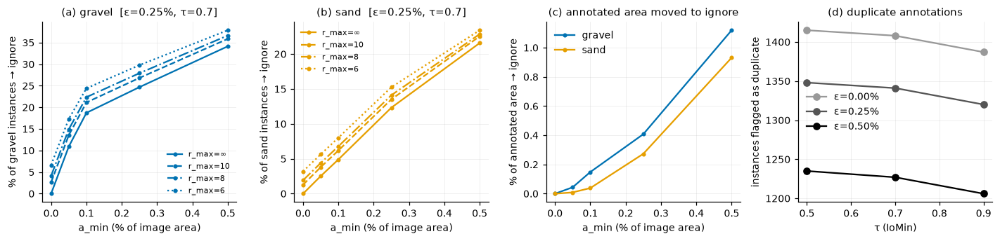

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
base = df_sens[(df_sens.eps == 0.0025) & (df_sens.tau == 0.7)]
for ax, name in zip(axes[:2], CLASS_NAMES):
    for r_max, ls in zip(RMAX_GRID, ["-", "--", "-.", ":"]):
        s = base[base.r_max == r_max].sort_values("a_min")
        n0 = s[f"kept_{name}"].iloc[0] + s[f"ignored_{name}"].iloc[0]
        ax.plot(s.a_min * 100, 100 * s[f"ignored_{name}"] / n0, ls, color=CLASS_COLORS[name], marker="o", ms=3,
                label=f"r_max={'∞' if np.isinf(r_max) else int(r_max)}")
    ax.set_xlabel("a_min (% of image area)"); ax.set_ylabel(f"% of {name} instances → ignore")
    ax.set_title(f"({'ab'[CLASS_NAMES.index(name)]}) {name}  [ε=0.25%, τ=0.7]"); ax.legend(frameon=False, fontsize=7)
for name in CLASS_NAMES:
    s = base[base.r_max == np.inf].sort_values("a_min")
    axes[2].plot(s.a_min * 100, 100 * s[f"ignored_area_share_{name}"], color=CLASS_COLORS[name], marker="o", ms=3, label=name)
axes[2].set_xlabel("a_min (% of image area)"); axes[2].set_ylabel("% of annotated area → ignore")
axes[2].set_title("(c) annotated area moved to ignore"); axes[2].legend(frameon=False)
dd = df_sens.groupby(["eps", "tau"]).duplicates.first().unstack()
for eps, col in zip(EPS_GRID, ["#999999", "#555555", "#000000"]):
    axes[3].plot(TAU_GRID, dd.loc[eps], marker="o", color=col, label=f"ε={eps*100:.2f}%")
axes[3].set_xlabel("τ (IoMin)"); axes[3].set_ylabel("instances flagged as duplicate"); axes[3].legend(frameon=False)
axes[3].set_title("(d) duplicate annotations")
fig.tight_layout(); savefig(fig, "fig10_silver_sensitivity"); plt.show()

saved figure: outputs/01_eda/df6d6fdc28/figures/fig11_opening_effect.png|pdf


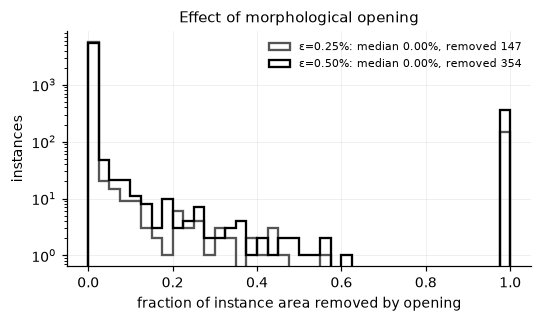

In [24]:
# ผลของ opening: สัดส่วนพื้นที่ที่เปลี่ยนไปต่อ instance เทียบกับ geometry ที่ซ่อมแล้วโดยไม่ทำ opening
a0 = stage_cache[(0.0, 0.7)]["area"]
fig, ax = plt.subplots(figsize=(5, 3))
for eps, col in zip(EPS_GRID[1:], ["#555555", "#000000"]):
    a1 = stage_cache[(eps, 0.7)]["area"]
    ok = a0 > 0
    change = 1 - a1[ok] / a0[ok]
    ax.hist(np.clip(change, 0, 1), bins=np.linspace(0, 1, 41), histtype="step", lw=1.5, color=col,
            label=f"ε={eps*100:.2f}%: median {np.median(change)*100:.2f}%, removed {(a1[ok]==0).sum()}")
ax.set_yscale("log"); ax.set_xlabel("fraction of instance area removed by opening"); ax.set_ylabel("instances")
ax.legend(frameon=False, fontsize=7); ax.set_title("Effect of morphological opening")
fig.tight_layout(); savefig(fig, "fig11_opening_effect"); plt.show()

saved figure: outputs/01_eda/df6d6fdc28/figures/fig12_silver_rule_examples.png|pdf


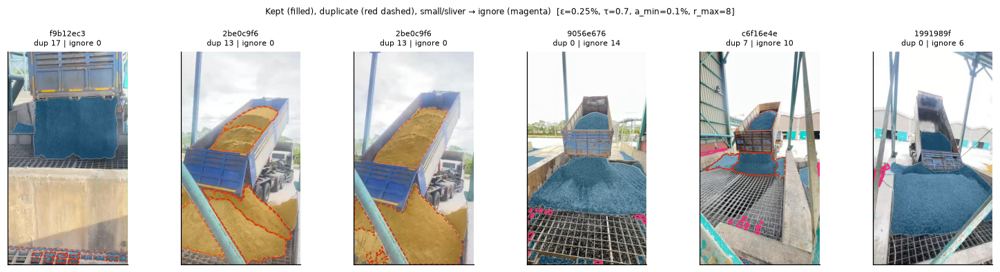

In [25]:
# ตัวอย่างสิ่งที่กฎลบหรือย้ายเป็น ignore ที่ค่ากลางของตาราง (ε=0.25%, τ=0.7, a_min=0.1%, r_max=8)
def rule_flags(eps, tau, a_min, r_max):
    st = stage_cache[(eps, tau)]
    frac = st["area"] / img_area
    alive = (~st["empty"]) & (st["dup_of"] < 0)
    small = alive & ((frac < a_min) | (st["aspect"] > r_max))
    return st, alive, small

st, alive, small = rule_flags(0.0025, 0.7, 0.001, 8)
dup = (st["dup_of"] >= 0) & ~st["empty"]
score = pd.DataFrame(dict(image_id=df_inst.image_id, dup=dup, small=small, empty=st["empty"])).groupby("image_id").sum()
pick = list(dict.fromkeys(score.nlargest(3, "dup").index.tolist() + score.nlargest(3, "small").index.tolist()))[:6]
fig, axes = plt.subplots(1, len(pick), figsize=(2.3 * len(pick), 3.6))
for ax, iid in zip(axes, pick):
    ax.imshow(cv2.cvtColor(cv2.imread(df_img.img_path[iid]), cv2.COLOR_BGR2RGB)); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for k in df_inst.index[df_inst.image_id == iid]:
        p = st["polys"][k]
        geom = p if p is not None else main_polygon(df_inst.geom[k] if df_inst.geom[k].is_valid else make_valid(df_inst.geom[k]))[0]
        if geom is None:
            continue
        xy = np.asarray(geom.exterior.coords)
        if alive[k] and not small[k]:
            ax.add_patch(MplPolygon(xy, facecolor=CLASS_COLORS[df_inst.cls_name[k]], alpha=0.35, edgecolor="white", lw=0.5))
        elif dup[k]:
            ax.add_patch(MplPolygon(xy, fill=False, edgecolor="#CC3311", ls="--", lw=1.0))
        elif small[k]:
            ax.add_patch(MplPolygon(xy, fill=False, edgecolor="#EE3377", lw=1.4))
    ax.set_title(f"{df_img.group_short[iid][:8]}\ndup {int(score.dup[iid])} | ignore {int(score.small[iid])}", fontsize=7)
fig.suptitle("Kept (filled), duplicate (red dashed), small/sliver → ignore (magenta)  [ε=0.25%, τ=0.7, a_min=0.1%, r_max=8]", fontsize=8)
fig.tight_layout(); savefig(fig, "fig12_silver_rule_examples"); plt.show()

## 9. การเลือกพารามิเตอร์ของ Silver

ผลจากหัวข้อ 8 (รูปที่ 10–12) นำไปสู่การตัดสินใจต่อไปนี้ ค่าทุกค่าเลือกจากการกระจายของข้อมูลและการตรวจด้วยตา ไม่ได้ใช้ผลของแบบจำลอง

| พารามิเตอร์ | ค่าที่เลือก | เหตุผล |
|---|---|---|
| ε (opening) | 0.25% ของด้านสั้น (≈0.9 px ที่ด้านสั้น 360 px) | ตัดเฉพาะส่วนยื่นที่แคบกว่าประมาณ 2 px ซึ่งต่ำกว่าความละเอียดที่ annotate ได้จริง; ค่า 0.5% เริ่มลบ instance ทั้งชิ้นเพิ่มขึ้นมาก (รูปที่ 11) |
| τ (annotation ซ้ำ) | IoMin ≥ 0.7 | จำนวน instance ที่ถูกระบุว่าซ้ำแทบไม่เปลี่ยนในช่วง 0.5–0.9 (รูปที่ 10d) ผลจึงไม่ไวต่อค่านี้ |
| การจัดการ annotation ซ้ำ | **รวมด้วย union** แทนการเก็บชิ้นที่ใหญ่ที่สุด | รูปที่ 12 แสดงว่า polygon ที่ซ้อนกันมักวาดกองวัสดุทั้งกองและส่วนย่อย การเก็บเฉพาะชิ้นใหญ่ที่สุด (กฎเดิม) ทิ้งพื้นที่ส่วนที่ยื่นออกนอกชิ้นใหญ่ |
| A_FLOOR (ตัดออกจากป้ายฝึก) | พื้นที่น้อยกว่าหนึ่ง cell ของ P3 ที่ input 640 (64 px² ต่อพื้นที่ภาพหลัง letterbox) | แบบจำลองแทนวัตถุที่เล็กกว่าหนึ่ง cell ของ feature map ละเอียดที่สุดไม่ได้ |
| A_MIN (ignore ในชุดประเมิน) | 0.1% ของพื้นที่ภาพ | จุดหักของกราฟใน gravel (รูปที่ 10a): สัดส่วน instance ที่ถูก ignore เพิ่มชันจนถึง 0.1% แล้วชะลอลง ขณะที่พื้นที่ที่ถูก ignore เป็นเพียง 0.15% (gravel) และ 0.04% (sand) ของพื้นที่ annotate ทั้งหมด (รูปที่ 10c) |
| R_MAX (sliver ในชุดประเมิน) | ไม่ใช้ (∞) | ฉบับร่างใช้ aspect > 10 (ร้อยละ 95 ของ instance มี aspect ≤ 6.9 ใน gravel และ ≤ 4.1 ใน sand) แต่การตรวจตัวอย่างในหัวข้อ 10.1 พบว่ากฎนี้จับแถบหินบนตะแกรงที่เห็นชัดและมีพื้นที่ 0.7–3% ของภาพ ขณะที่ชิ้นบางขนาดเล็กถูกจับโดย A_MIN อยู่แล้ว จึงตัดกฎนี้ออก |

**การใช้กับแต่ละชุด**

- **ป้ายฝึก (YOLO labels):** เก็บทุก instance ที่ซ่อมแล้ว รวม annotation ซ้ำแล้ว และมีพื้นที่ ≥ A_FLOOR instance ระหว่าง A_FLOOR และ A_MIN ยังคงอยู่ในป้ายฝึก เพื่อไม่ให้พิกเซลของวัสดุจริงถูกสอนเป็นพื้นหลัง
- **GT สำหรับประเมิน (COCO JSON):** instance ที่มีพื้นที่ ≥ A_MIN เป็น GT ปกติ ส่วน instance อื่นที่ไม่ว่างเป็น `iscrowd=1` (ignore region)
- กฎเดียวกันใช้กับทุก split และจะใช้กับชุด holdout ใน Notebook 04

**Limitation** การแยกเกณฑ์ระหว่างป้ายฝึกและ GT ประเมินเป็นการออกแบบที่ต้องเปิดเผย ผลแบบ strict (นับ GT ทุกชิ้นที่ ≥ A_FLOOR) จะรายงานคู่กันใน Notebook 03 และ 04

In [26]:
SILVER_PARAMS = dict(eps_frac=0.0025, tau_iomin=0.7, dup_merge="union",
                     a_floor_px640=64.0, a_min_frac=0.001, r_max_eval=float("inf"))
AUDIT_R_MAX = 10.0   # เกณฑ์ aspect ของกฎฉบับร่าง (v1) ใช้กำหนดชั้นของการตรวจตัวอย่างในหัวข้อ 10.1
CONFIG["silver"] = SILVER_PARAMS
print(json.dumps(SILVER_PARAMS, indent=2))

{
  "eps_frac": 0.0025,
  "tau_iomin": 0.7,
  "dup_merge": "union",
  "a_floor_px640": 64.0,
  "a_min_frac": 0.001,
  "r_max_eval": Infinity
}


## 10. การสร้างชุดข้อมูล Silver

**Method** ใช้กฎในหัวข้อ 9 ตามลำดับ: ซ่อม geometry → opening → รวม annotation ซ้ำด้วย union (union-find ของคู่ IoMin ≥ τ ภายในคลาสเดียวกัน) → กำหนดบทบาทของแต่ละ instance (`train_and_eval`, `train_only_ignore_eval`, `dropped`) แล้วเขียน label ใหม่ ตรวจโดยอ่านกลับจากดิสก์

**Implementation** ภาพคัดลอกจาก bronze โดยไม่แก้ไข ชื่อไดเรกทอรีมี hash ของเนื้อหา (SHA-256 ของภาพและ label ทั้งหมดรวมกับพารามิเตอร์) ถ้ามีชุดที่ hash ตรงกันอยู่แล้วจะไม่เขียนซ้ำ

**Limitation** union ของ polygon ที่ไม่ต่อกันเป็นชิ้นเดียวจะถูกแยกเป็นหลาย instance (หนึ่ง instance ต่อชิ้น) ตามรูปแบบ YOLO ที่ไม่รองรับ polygon หลายชิ้นหรือมีรู

In [27]:
P = SILVER_PARAMS
silver_rows = []
for iid, idx in df_inst.groupby("image_id").indices.items():
    r = df_img.loc[iid]
    W, Hh = int(r.width), int(r.height)
    letter_scale = 640 / max(W, Hh)
    a_floor_frac = P["a_floor_px640"] / ((W * letter_scale) * (Hh * letter_scale))
    geoms, cls = [], []
    for k in idx:
        poly, _ = clean_geometry(df_inst.geom.values[k], min(W, Hh), P["eps_frac"])
        if poly is not None:
            geoms.append(poly); cls.append(int(df_inst.cls.values[k]))
    # union-find ของ instance คลาสเดียวกันที่ IoMin >= tau
    par = list(range(len(geoms)))
    def f(x):
        while par[x] != x:
            par[x] = par[par[x]]; x = par[x]
        return x
    for a in range(len(geoms)):
        for b in range(a + 1, len(geoms)):
            if cls[a] != cls[b] or not geoms[a].intersects(geoms[b]):
                continue
            inter = geoms[a].intersection(geoms[b]).area
            if inter / max(min(geoms[a].area, geoms[b].area), 1e-9) >= P["tau_iomin"]:
                par[f(a)] = f(b)
    clusters = defaultdict(list)
    for a in range(len(geoms)):
        clusters[f(a)].append(a)
    for members in clusters.values():
        u = shapely.union_all([geoms[m] for m in members]) if len(members) > 1 else geoms[members[0]]
        u = u if u.is_valid else make_valid(u)
        parts = [p for p in (u.geoms if hasattr(u, "geoms") else [u]) if p.geom_type == "Polygon" and p.area > 0]
        for p in parts:
            p = Polygon(p.exterior)                       # YOLO ไม่รองรับรู จึงใช้ขอบนอก
            frac = p.area / (W * Hh)
            asp = mrr_aspect(p)
            if frac < a_floor_frac:
                role = "dropped"
            elif frac < P["a_min_frac"] or asp > P["r_max_eval"]:
                role = "train_only_ignore_eval"
            else:
                role = "train_and_eval"
            silver_rows.append(dict(image_id=iid, cls=cls[members[0]], cls_name=CLASS_NAMES[cls[members[0]]],
                                    n_merged=len(members), area_frac=frac, aspect=asp, role=role, geom=p))
df_silver = pd.DataFrame(silver_rows)
role_tab = pd.crosstab(df_silver.cls_name, df_silver.role, margins=True)
save_table(role_tab.reset_index(), "silver_roles")
print(f"bronze instances: {len(df_inst)} -> silver instances: {len(df_silver)} "
      f"(merged clusters with >1 member: {(df_silver.n_merged > 1).sum()})")
display(role_tab)

saved table: outputs/01_eda/df6d6fdc28/tables/silver_roles.csv  (3 rows)
bronze instances: 6023 -> silver instances: 4375 (merged clusters with >1 member: 907)


role,dropped,train_and_eval,train_only_ignore_eval,All
cls_name,,,,
gravel,155,1786,253,2194
sand,35,2075,71,2181
All,190,3861,324,4375


In [28]:
# พื้นที่ที่ได้คืนจากการรวมด้วย union เทียบกับกฎเดิม (เก็บชิ้นที่ใหญ่ที่สุด) ในชุดเดียวกัน
st_old = stage_cache[(P["eps_frac"], P["tau_iomin"])]
old_area = pd.Series(st_old["area"] * ((~st_old["empty"]) & (st_old["dup_of"] < 0))).groupby(df_inst.image_id.values).sum()
new_area = df_silver[df_silver.role != "dropped"].assign(a=lambda d: d.geom.apply(lambda g: g.area)).groupby("image_id").a.sum()
gain = (new_area / old_area.reindex(new_area.index)).replace([np.inf], np.nan) - 1
print(f"annotated area: union vs keep-largest  median {gain.median()*100:.2f}%  |  95th pct {gain.quantile(.95)*100:.2f}%  |  max {gain.max()*100:.1f}%")

annotated area: union vs keep-largest  median 0.00%  |  95th pct 1.26%  |  max 11.6%


In [29]:
def dataset_hash(df_s, params):
    h = hashlib.sha256(json.dumps(params, sort_keys=True).encode())
    for iid in sorted(df_img.image_id):
        h.update(df_img.sha256[iid].encode())
        sub = df_s[(df_s.image_id == iid) & (df_s.role != "dropped")]
        for g in sub.sort_values(["cls", "area_frac"]).itertuples():
            h.update(f"{g.cls}:{g.role}:{g.geom.wkt}".encode())
    return h.hexdigest()[:12]

SILVER_HASH = dataset_hash(df_silver, P)
SILVER_DIR = ROOT / "data" / f"silver_{SILVER_HASH}"
CONFIG["silver_hash"] = SILVER_HASH

def rounded_valid_xy(poly, W, Hh, nd=6):
    # ปัดพิกัดเป็นทศนิยม 6 ตำแหน่งตามรูปแบบไฟล์ แล้วซ่อมถ้าการปัดทำให้ polygon ตัดกันเอง
    for _ in range(3):
        xy = np.clip(np.round(np.asarray(poly.exterior.coords)[:-1] / [W, Hh], nd), 0, 1)
        q = Polygon(xy * [W, Hh])
        if q.is_valid and q.area > 0:
            return xy
        poly, _ = main_polygon(make_valid(q))
        if poly is None:
            return None
    return None

def yolo_line(cls, poly, W, Hh):
    xy = rounded_valid_xy(poly, W, Hh)
    return None if xy is None else f"{cls} " + " ".join(f"{v:.6f}" for v in xy.ravel())

# ชื่อไฟล์ใน Silver: <image_id 4 หลัก>__<ชื่อเดิม> เพื่อให้ไม่ชนกันและสืบย้อนได้
df_img["silver_name"] = [f"{i:04d}__{f}" for i, f in zip(df_img.image_id, df_img.file)]
if (SILVER_DIR / "silver_meta.json").exists():
    print(f"Silver already exists, not rewritten: {SILVER_DIR.relative_to(ROOT)}")
else:
    (SILVER_DIR / "images").mkdir(parents=True, exist_ok=True); (SILVER_DIR / "labels").mkdir(exist_ok=True)
    import shutil
    for r in df_img.itertuples():
        shutil.copy2(r.img_path, SILVER_DIR / "images" / r.silver_name)
        sub = df_silver[(df_silver.image_id == r.image_id) & (df_silver.role != "dropped")]
        lines = [l for l in (yolo_line(g.cls, g.geom, r.width, r.height) for g in sub.itertuples()) if l is not None]
        (SILVER_DIR / "labels" / (Path(r.silver_name).stem + ".txt")).write_text("\n".join(lines) + ("\n" if lines else ""))
    inst_out = df_silver.assign(wkt=df_silver.geom.apply(lambda g: g.wkt), image=df_silver.image_id.map(df_img.silver_name)).drop(columns="geom")
    inst_out.to_csv(SILVER_DIR / "silver_instances.csv", index=False)
    (SILVER_DIR / "silver_meta.json").write_text(json.dumps(dict(
        silver_hash=SILVER_HASH, params=P, source=str(BRONZE), roboflow="aggregate_rock-and-sand v5 (CC BY 4.0)",
        n_images=len(df_img), n_instances=int((df_silver.role != "dropped").sum()),
        roles=df_silver.role.value_counts().to_dict(), created=time.strftime("%Y-%m-%dT%H:%M:%S%z"),
        classes=CLASS_NAMES), indent=2))
    print(f"Silver written: {SILVER_DIR.relative_to(ROOT)}")

Silver already exists, not rewritten: data/silver_0997f3096843


In [30]:
# ตรวจ Silver โดยอ่านกลับจากดิสก์
chk_rows = []
for r in df_img.itertuples():
    lp = SILVER_DIR / "labels" / (Path(r.silver_name).stem + ".txt")
    for line in lp.read_text().splitlines():
        t = line.split(); c = int(t[0]); xy = np.asarray(t[1:], float).reshape(-1, 2)
        p = Polygon(xy * [r.width, r.height])
        chk_rows.append(dict(image_id=r.image_id, cls=c, n=len(xy), inrange=bool(((xy >= 0) & (xy <= 1)).all()),
                             valid=p.is_valid, area=p.area))
df_chk = pd.DataFrame(chk_rows)
checks = {
    "image files copied": len(list((SILVER_DIR / "images").iterdir())) == len(df_img),
    "label count == silver kept instances": len(df_chk) == int((df_silver.role != "dropped").sum()),
    "all polygons >= 3 vertices": bool((df_chk.n >= 3).all()),
    "all coordinates in [0,1]": bool(df_chk.inrange.all()),
    "class ids in {0,1}": bool(df_chk.cls.isin([0, 1]).all()),
    "all polygons valid": bool(df_chk.valid.all()),
    "no zero-area polygons": bool((df_chk.area > 0).all()),
}
for k, v in checks.items():
    print(("PASS " if v else "FAIL ") + k)
n_invalid = int((~df_chk.valid).sum())
if n_invalid:
    print(f"invalid after coordinate rounding: {n_invalid} -> listed for inspection")
assert all(v for k, v in checks.items() if k != "all polygons valid"), "Silver integrity check failed"

PASS image files copied
PASS label count == silver kept instances
PASS all polygons >= 3 vertices
PASS all coordinates in [0,1]
PASS class ids in {0,1}
PASS all polygons valid
PASS no zero-area polygons


saved figure: outputs/01_eda/df6d6fdc28/figures/fig13_bronze_vs_silver.png|pdf


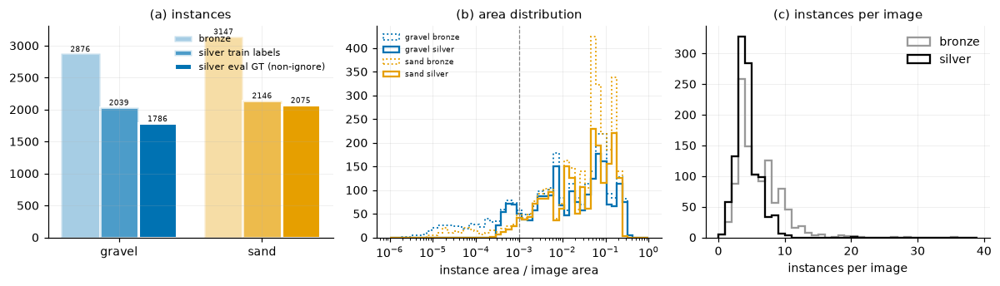

In [31]:
# เปรียบเทียบ bronze กับ Silver
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
b = df_inst.cls_name.value_counts().reindex(CLASS_NAMES)
s_train = df_silver[df_silver.role != "dropped"].cls_name.value_counts().reindex(CLASS_NAMES)
s_eval = df_silver[df_silver.role == "train_and_eval"].cls_name.value_counts().reindex(CLASS_NAMES)
x = np.arange(2); w = 0.27
for k, (v, lab, a) in enumerate([(b, "bronze", 0.35), (s_train, "silver train labels", 0.7), (s_eval, "silver eval GT (non-ignore)", 1.0)]):
    bars = axes[0].bar(x + (k - 1) * w, v.values, w, color=[CLASS_COLORS[c] for c in CLASS_NAMES], alpha=a, label=lab, edgecolor="white", lw=2)
    axes[0].bar_label(bars, fontsize=6)
axes[0].set_xticks(x, CLASS_NAMES); axes[0].legend(frameon=False, fontsize=7); axes[0].set_title("(a) instances")
bins = np.logspace(-6, 0, 50)
for c in CLASS_NAMES:
    axes[1].hist(df_inst.loc[df_inst.cls_name == c, "area_frac"], bins=bins, histtype="step", color=CLASS_COLORS[c], ls=":", lw=1.2, label=f"{c} bronze")
    axes[1].hist(df_silver.loc[(df_silver.cls_name == c) & (df_silver.role != "dropped"), "area_frac"], bins=bins, histtype="step",
                 color=CLASS_COLORS[c], lw=1.5, label=f"{c} silver")
axes[1].axvline(P["a_min_frac"], color="#888888", ls="--", lw=0.8); axes[1].set_xscale("log")
axes[1].set_xlabel("instance area / image area"); axes[1].legend(frameon=False, fontsize=6); axes[1].set_title("(b) area distribution")
ipi_b = df_inst.groupby("image_id").size().reindex(df_img.image_id, fill_value=0)
ipi_s = df_silver[df_silver.role != "dropped"].groupby("image_id").size().reindex(df_img.image_id, fill_value=0)
axes[2].hist(ipi_b, bins=np.arange(0, 40), histtype="step", color="#999999", lw=1.5, label="bronze")
axes[2].hist(ipi_s, bins=np.arange(0, 40), histtype="step", color="#000000", lw=1.5, label="silver")
axes[2].set_xlabel("instances per image"); axes[2].legend(frameon=False); axes[2].set_title("(c) instances per image")
fig.tight_layout(); savefig(fig, "fig13_bronze_vs_silver"); plt.show()

saved figure: outputs/01_eda/df6d6fdc28/figures/fig14_bronze_vs_silver_examples.png|pdf


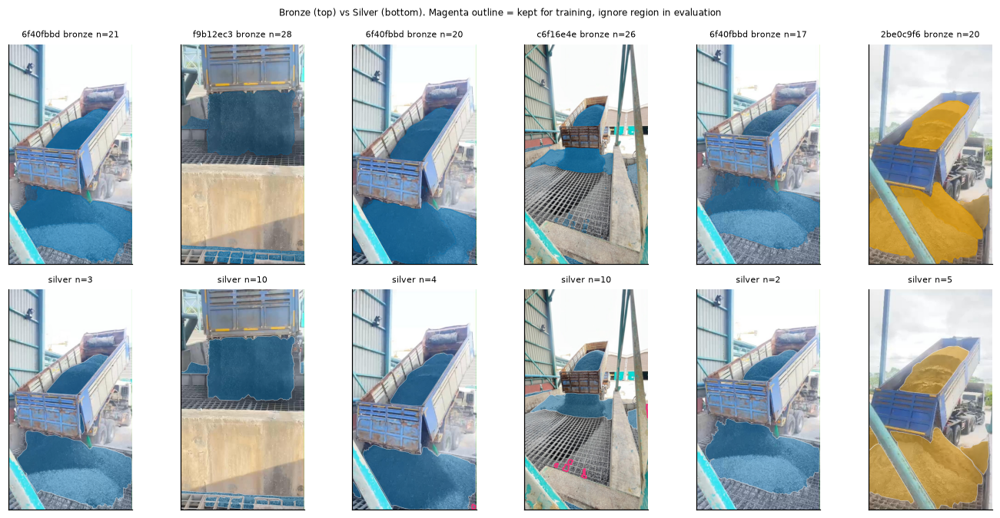

In [32]:
# ภาพเปรียบเทียบ bronze (บน) กับ Silver (ล่าง) ของภาพที่เปลี่ยนแปลงมากที่สุด
chg = (ipi_b - ipi_s).sort_values(ascending=False)
pick = chg.index[:6].tolist()
fig, axes = plt.subplots(2, 6, figsize=(12.5, 6.2))
for c, iid in enumerate(pick):
    im = cv2.cvtColor(cv2.imread(df_img.img_path[iid]), cv2.COLOR_BGR2RGB)
    for rr in range(2):
        ax = axes[rr, c]; ax.imshow(im); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    draw_polys(axes[0, c], iid, lw=0.8, alpha=0.25)
    for g in df_silver[df_silver.image_id == iid].itertuples():
        xy = np.asarray(g.geom.exterior.coords)
        if g.role == "train_and_eval":
            axes[1, c].add_patch(MplPolygon(xy, facecolor=CLASS_COLORS[g.cls_name], alpha=0.4, edgecolor="white", lw=0.6))
        elif g.role == "train_only_ignore_eval":
            axes[1, c].add_patch(MplPolygon(xy, fill=False, edgecolor="#EE3377", lw=1.2))
    axes[0, c].set_title(f"{df_img.group_short[iid][:8]} bronze n={ipi_b[iid]}", fontsize=7)
    axes[1, c].set_title(f"silver n={ipi_s[iid]}", fontsize=7)
fig.suptitle("Bronze (top) vs Silver (bottom). Magenta outline = kept for training, ignore region in evaluation", fontsize=8)
fig.tight_layout(); savefig(fig, "fig14_bronze_vs_silver_examples"); plt.show()

### 10.1 การตรวจกฎ Silver จากตัวอย่างสุ่ม

**Method** สุ่มตัวอย่างแบบแบ่งชั้นตามบทบาทของ instance ชั้นละ 30 ชิ้น (seed 42) ได้แก่ (ก) instance ที่เกิดจากการรวมหลายชิ้น (ข) instance ที่เป็น ignore ในชุดประเมิน (ค) instance ที่ถูกตัดออก (ง) instance ที่ไม่ถูกแก้ไข แล้วแสดงภาพตัดเฉพาะบริเวณพร้อม polygon ของ Silver (ระบายสี) และ polygon เดิมของ bronze (เส้นประ) ผู้ตรวจตัดสินแต่ละชิ้นเป็น `accept`, `reject` หรือ `unsure` ตามเกณฑ์ของแต่ละชั้น

| ชั้น | เกณฑ์ accept |
|---|---|
| merged | polygon ที่รวมแล้วครอบคลุมบริเวณวัสดุเดียวกับ polygon เดิม และไม่รวมบริเวณที่ไม่ใช่วัสดุเพิ่ม |
| ignore_eval | เป็นเศษวัสดุขนาดเล็กหรือแถบบางที่ขอบเขตกำกวม การไม่นับในชุดประเมินจึงสมเหตุสมผล |
| dropped | เป็นเศษหรือ polygon ผิดรูปที่ไม่มีข้อมูลที่ใช้ฝึกได้ |
| unchanged | ขอบเขตและคลาสสอดคล้องกับภาพ |

รายงานสัดส่วน `reject` ของแต่ละชั้นพร้อมช่วงความเชื่อมั่น 95% แบบ Wilson

**Implementation** ชั้น `ignore_eval` ของการตรวจกำหนดตามกฎฉบับร่าง (A_MIN หรือ aspect > 10) เพราะการตรวจทำก่อนตัดสินใจเรื่องกฎ aspect ผลการตรวจเป็นเหตุผลของการตัดกฎ aspect ในหัวข้อ 9

**Limitation** การตรวจรอบนี้ทำโดยผู้ช่วยวิจัย (Claude) จากภาพตัด ไม่ใช่ผู้ตรวจที่เป็นมนุษย์อิสระ และมีผู้ตรวจเพียงหนึ่งราย จึงคำนวณความสอดคล้องระหว่างผู้ตรวจไม่ได้ ผลใช้ได้เป็นการตรวจคุณภาพเบื้องต้นของกฎเท่านั้น ไฟล์ผลการตรวจคือ `manifests/silver_audit_review_v1.csv` ซึ่งผู้วิจัยแก้ไขหรือเพิ่มผู้ตรวจคนที่สองได้

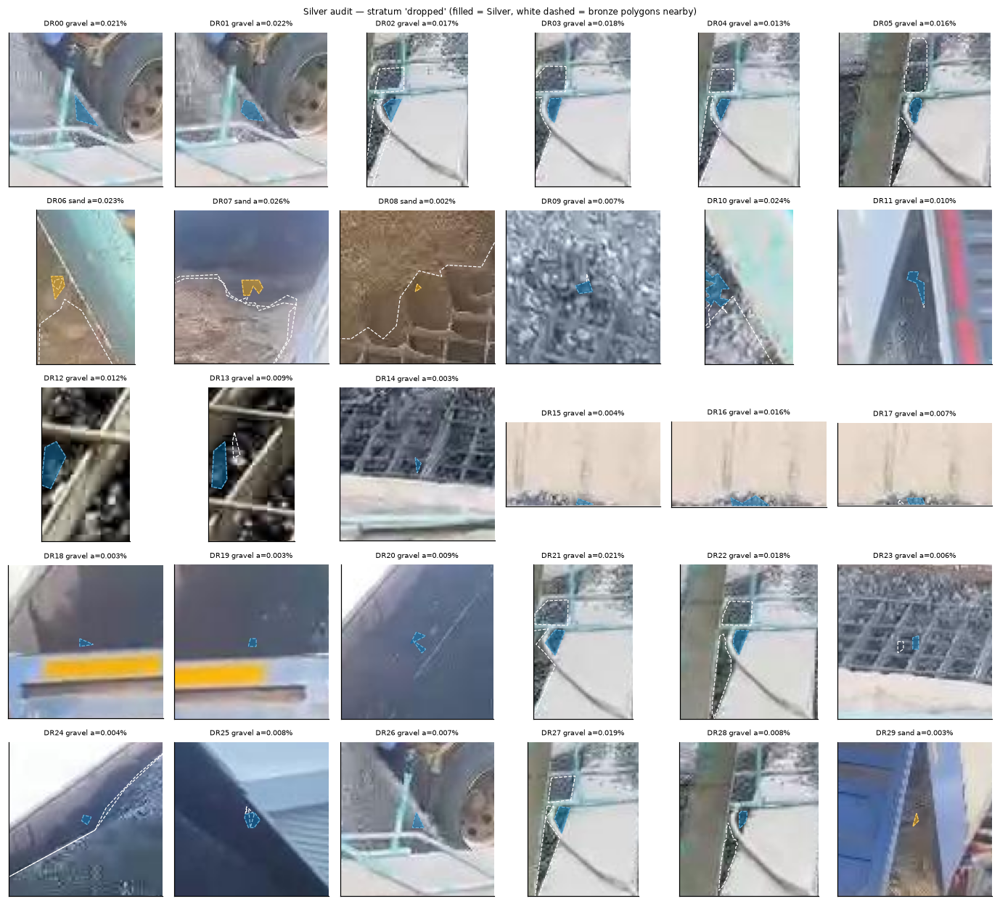

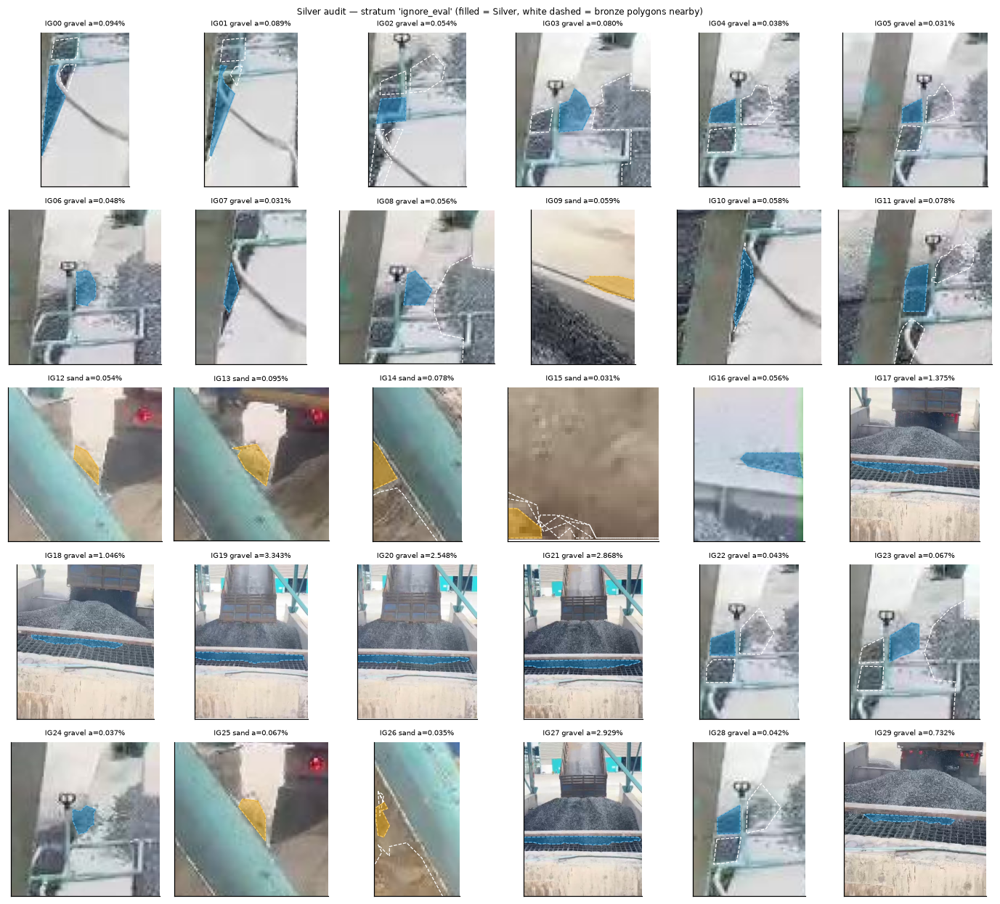

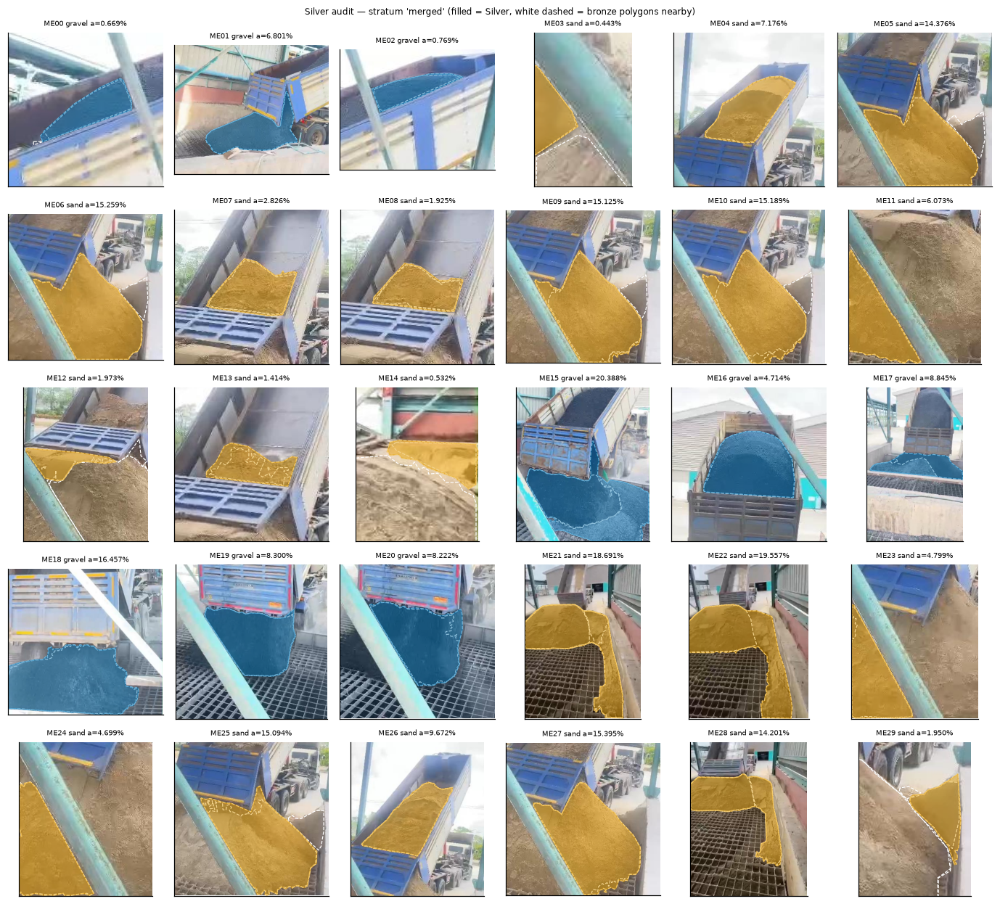

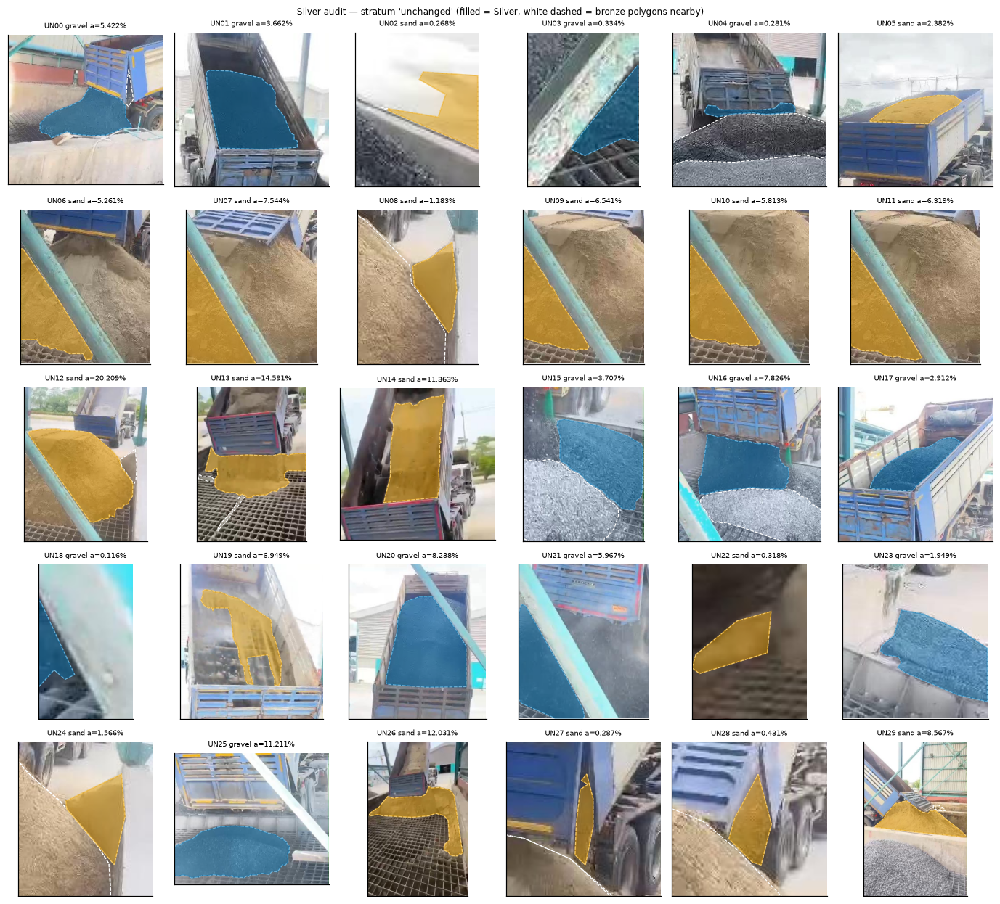

audit sample: manifests/silver_audit_0997f3096843.csv 120 | galleries: outputs/01_eda/df6d6fdc28/silver_audit


In [33]:
AUDIT_N = 30
rng_a = np.random.default_rng(SEED)
# ชั้นของการตรวจกำหนดด้วยกฎฉบับร่าง v1 (A_MIN หรือ aspect > AUDIT_R_MAX) เพื่อให้ตัวอย่างที่ตรวจแล้วสุ่มได้ซ้ำ
cand_ignore = (df_silver.role != "dropped") & ((df_silver.area_frac < P["a_min_frac"]) | (df_silver.aspect > AUDIT_R_MAX))
df_silver["stratum"] = np.select([df_silver.role == "dropped", cand_ignore, df_silver.n_merged > 1],
                                 ["dropped", "ignore_eval", "merged"], default="unchanged")
df_silver["ignore_by"] = np.where(df_silver.area_frac < P["a_min_frac"], "area", np.where(df_silver.aspect > AUDIT_R_MAX, "aspect_only", ""))
parts = []
for stratum in ["merged", "ignore_eval", "dropped", "unchanged"]:
    d = df_silver[df_silver.stratum == stratum]
    parts.append(d.iloc[np.sort(rng_a.choice(len(d), size=min(AUDIT_N, len(d)), replace=False))])
audit = pd.concat(parts).reset_index().rename(columns={"index": "silver_idx"})
audit["audit_id"] = [f"{s[:2].upper()}{k:02d}" for s, k in zip(audit.stratum, audit.groupby("stratum").cumcount())]
AUD_DIR = OUT / "silver_audit"; AUD_DIR.mkdir(exist_ok=True)

def audit_tile(row, size=170):
    r = df_img.loc[row.image_id]
    im = cv2.cvtColor(cv2.imread(r.img_path), cv2.COLOR_BGR2RGB)
    minx, miny, maxx, maxy = row.geom.bounds
    cx, cy = (minx + maxx) / 2, (miny + maxy) / 2
    half = max(maxx - minx, maxy - miny, 48) * 0.85
    x0, y0 = int(max(0, cx - half)), int(max(0, cy - half))
    x1, y1 = int(min(r.width, cx + half)), int(min(r.height, cy + half))
    return im, (x0, y0, x1, y1)

for stratum, sub in audit.groupby("stratum"):
    n = len(sub); ncol = 6; nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * 2.1, nrow * 2.3))
    for ax, row in zip(axes.ravel(), sub.itertuples()):
        im, (x0, y0, x1, y1) = audit_tile(row)
        ax.imshow(im); ax.set_xlim(x0, x1); ax.set_ylim(y1, y0); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for b in df_inst[df_inst.image_id == row.image_id].itertuples():
            pg, _ = main_polygon(b.geom if b.geom.is_valid else make_valid(b.geom))
            if pg is not None and pg.intersects(row.geom.buffer(5)):
                ax.add_patch(MplPolygon(np.asarray(pg.exterior.coords), fill=False, edgecolor="white", ls="--", lw=0.8))
        ax.add_patch(MplPolygon(np.asarray(row.geom.exterior.coords), facecolor=CLASS_COLORS[row.cls_name], alpha=0.45,
                                edgecolor=CLASS_COLORS[row.cls_name], lw=1.2))
        ax.set_title(f"{row.audit_id} {row.cls_name} a={row.area_frac*100:.3f}%", fontsize=6.5)
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    fig.suptitle(f"Silver audit — stratum '{stratum}' (filled = Silver, white dashed = bronze polygons nearby)", fontsize=8)
    fig.tight_layout(); fig.savefig(AUD_DIR / f"audit_{stratum}.png", dpi=170, bbox_inches="tight"); plt.show()

AUDIT_FILE = ROOT / "manifests" / f"silver_audit_{SILVER_HASH}.csv"
audit[["audit_id", "stratum", "image_id", "cls_name", "area_frac", "aspect", "n_merged", "role", "ignore_by"]].assign(
    image=lambda d: d.image_id.map(df_img.silver_name)).to_csv(AUDIT_FILE, index=False)
print("audit sample:", AUDIT_FILE.relative_to(ROOT), len(audit), "| galleries:", AUD_DIR.relative_to(ROOT))

In [34]:
from statsmodels.stats.proportion import proportion_confint
REVIEW_FILE = ROOT / "manifests" / "silver_audit_review_v1.csv"
if REVIEW_FILE.exists():
    rev = pd.read_csv(REVIEW_FILE)
    key_a = set(zip(audit.audit_id, audit.image_id.map(df_img.silver_name)))
    assert set(zip(rev.audit_id, rev.image)) == key_a, "review file does not match the audit sample"
    rows = []
    for stratum, d in rev.merge(audit[["audit_id", "stratum"]], on="audit_id").groupby("stratum"):
        n = len(d); rej = int((d.decision == "reject").sum()); uns = int((d.decision == "unsure").sum())
        lo, hi = proportion_confint(rej, n, alpha=0.05, method="wilson")
        rows.append(dict(stratum=stratum, n=n, accept=int((d.decision == "accept").sum()), reject=rej, unsure=uns,
                         reject_rate=rej / n, reject_ci95_low=lo, reject_ci95_high=hi, reviewer=",".join(sorted(d.reviewer.unique()))))
    audit_res = pd.DataFrame(rows)
    save_table(audit_res, "silver_audit_result")
    display(audit_res.round(3))
    display(rev[rev.decision != "accept"])
    ig = rev.merge(audit[["audit_id", "stratum", "ignore_by", "role"]], on="audit_id")
    ig = ig[ig.stratum == "ignore_eval"]
    print("ignore stratum by criterion (draft rule v1):")
    display(pd.crosstab(ig.ignore_by, ig.decision))
    print("role of these instances under the final rule:", ig.role.value_counts().to_dict())
else:
    print(f"review file not found: {REVIEW_FILE.relative_to(ROOT)} — audit galleries are ready for review")

saved table: outputs/01_eda/df6d6fdc28/tables/silver_audit_result.csv  (4 rows)


,stratum,n,accept,reject,unsure,reject_rate,reject_ci95_low,reject_ci95_high,reviewer
0,dropped,30,30,0,0,0.000,0.000,0.114,claude-ai-visual
1,ignore_eval,30,23,7,0,0.233,0.118,0.409,claude-ai-visual
2,merged,30,27,0,3,0.000,0.000,0.114,claude-ai-visual
3,unchanged,30,28,0,2,0.000,0.000,0.114,claude-ai-visual


,audit_id,image,decision,note,reviewer,reviewed,method
3,ME03,0201__2be0c9f6-caf7-4f26-9b59-b1299865a721_mp4...,unsure,nearby bronze polygon extends below the merged...,claude-ai-visual,2026-10-18,visual inspection of audit gallery crops (outp...
14,ME14,0429__4a7f29af-8d1c-4a3b-90e6-b9cf771fd1c2_mp4...,unsure,merged polygon covers only the upper strip; la...,claude-ai-visual,2026-10-18,visual inspection of audit gallery crops (outp...
29,ME29,1021__2be0c9f6-caf7-4f26-9b59-b1299865a721_mp4...,unsure,boundary along pole uncertain; adjacent bronze...,claude-ai-visual,2026-10-18,visual inspection of audit gallery crops (outp...
47,IG17,0645__d56fcb3c-0531-4696-8b67-2645d89e4a7f_mp4...,reject,clearly visible gravel strip on grating (area ...,claude-ai-visual,2026-10-18,visual inspection of audit gallery crops (outp...
48,IG18,0650__d56fcb3c-0531-4696-8b67-2645d89e4a7f_mp4...,reject,clearly visible gravel strip on grating (area ...,claude-ai-visual,2026-10-18,visual inspection of audit gallery crops (outp...
49,IG19,0662__d56fcb3c-0531-4696-8b67-2645d89e4a7f_mp4...,reject,clearly visible gravel strip on grating (area ...,claude-ai-visual,2026-10-18,visual inspection of audit gallery crops (outp...
50,IG20,0665__d56fcb3c-0531-4696-8b67-2645d89e4a7f_mp4...,reject,clearly visible gravel strip on grating (area ...,claude-ai-visual,2026-10-18,visual inspection of audit gallery crops (outp...
51,IG21,0678__d56fcb3c-0531-4696-8b67-2645d89e4a7f_mp4...,reject,clearly visible gravel strip on grating (area ...,claude-ai-visual,2026-10-18,visual inspection of audit gallery crops (outp...
57,IG27,0955__d56fcb3c-0531-4696-8b67-2645d89e4a7f_mp4...,reject,clearly visible gravel strip on grating (area ...,claude-ai-visual,2026-10-18,visual inspection of audit gallery crops (outp...
59,IG29,1073__d56fcb3c-0531-4696-8b67-2645d89e4a7f_mp4...,reject,clearly visible gravel strip on grating (area ...,claude-ai-visual,2026-10-18,visual inspection of audit gallery crops (outp...


ignore stratum by criterion (draft rule v1):


decision,accept,reject
ignore_by,,
area,23,0
aspect_only,0,7


role of these instances under the final rule: {'train_only_ignore_eval': 23, 'train_and_eval': 7}


## 11. ป้ายสถานะระดับภาพ (frame-state) สำหรับการประเมิน L2

**Method** คลาส c ถือว่าปรากฏในภาพเมื่อผลรวมพื้นที่ของ instance คลาส c ที่เป็น GT ปกติ (`train_and_eval`) มีค่าอย่างน้อย A_MIN จากนั้นแปลงเป็นสี่สถานะ: `none`, `gravel`, `sand`, `mixed`

**Rationale** การใช้งานจริงต้องการสถานะของวัสดุ ณ เวลาหนึ่ง ไม่ใช่ขอบเขตของ instance (RESEARCH_PLAN หัวข้อ 9.2) การประเมินระดับภาพสำหรับระบบที่ใช้ segmentation แล้วตัดสินระดับภาพมีตัวอย่างในงานอุตสาหกรรม (Tabernik et al., 2020, *J. Intell. Manuf.* 31: 759–776) และการแยก metric ตามประเภทของปัญหาเป็นข้อแนะนำของ Maier-Hein et al. (2024), *Nature Methods* 21: 195–212

**Limitation** ชุดพัฒนาแทบไม่มีภาพสถานะ `none` จึงประเมินสถานะนี้จากชุดพัฒนาไม่ได้ ต้องใช้เฟรมจากวิดีโอหรือชุด S02 ใน Notebook 04

In [35]:
pres = (df_silver[df_silver.role == "train_and_eval"].groupby(["image_id", "cls_name"]).area_frac.sum()
        .unstack(fill_value=0).reindex(df_img.image_id, fill_value=0))
for c in CLASS_NAMES:
    if c not in pres:
        pres[c] = 0.0
A = P["a_min_frac"]
df_img["state"] = [("mixed" if g >= A and s >= A else "gravel" if g >= A else "sand" if s >= A else "none")
                   for g, s in zip(pres.gravel, pres.sand)]
state_tab = pd.crosstab(df_img.group_merged.str[:8], df_img.state)
state_tab = state_tab.loc[df_img.groupby(df_img.group_merged.str[:8]).size().sort_values(ascending=False).index]
save_table(state_tab.reset_index(), "frame_state_by_group")
print(df_img.state.value_counts().to_dict())
display(state_tab)

saved table: outputs/01_eda/df6d6fdc28/tables/frame_state_by_group.csv  (27 rows)
{'gravel': 489, 'sand': 483, 'mixed': 112, 'none': 5}


state,gravel,mixed,none,sand
group_merged,,,,
2be0c9f6,0,0,1,315
0f964fdb,111,0,0,0
0a48349e,0,0,0,81
96ecd4fe,62,0,4,0
1991989f,8,57,0,0
b029e315,59,0,0,0
d56fcb3c,57,0,0,0
f9b12ec3,56,0,0,0
6459c886,0,0,0,49


## 12. การทดลองกลยุทธ์การแบ่งชุดข้อมูล

**Method** เปรียบเทียบสี่กลยุทธ์บนหน่วยกลุ่มที่รวมแล้วในหัวข้อ 3.1

- **S0** การแบ่งเดิมของ Roboflow (สุ่มระดับภาพ)
- **S1** `GroupShuffleSplit` (สุ่มระดับกลุ่ม) 1,000 seeds เพื่อดูการกระจายของผลลัพธ์
- **S2** `StratifiedGroupKFold` 5 fold โดยใช้สถานะของภาพเป็น y
- **S3** การแบ่งระดับกลุ่มภายใต้เงื่อนไข ค้นหาด้วยการสุ่ม 20,000 ครั้ง (seed 42)

ตัวชี้วัดของทุกกลยุทธ์

- จำนวนกลุ่มที่อยู่ข้าม split
- จำนวนคู่ภาพเกือบซ้ำ (d ≤ `D_ND`) ข้าม split
- ระยะ pHash จากภาพทดสอบแต่ละภาพไปยังภาพฝึกที่ใกล้ที่สุด
- สัดส่วนภาพของแต่ละ split
- ความต่างของการกระจายสถานะ (Jensen–Shannon divergence) เทียบกับทั้งชุด
- จำนวนกลุ่มที่มี sand ในแต่ละ split

**Rationale** การสุ่มระดับภาพของข้อมูลที่มีโครงสร้างกลุ่มทำให้ประเมินความคลาดเคลื่อนต่ำเกินจริง (Roberts et al., 2017) แต่เมื่อมีจำนวนกลุ่มน้อยและกลุ่มมีขนาดต่างกันมาก การสุ่มระดับกลุ่มอาจได้ชุดทดสอบที่ไม่มีคลาสใดคลาสหนึ่งเลย เอกสาร scikit-learn ระบุว่า `StratifiedGroupKFold` จะทำ stratification ไม่ได้และมีพฤติกรรมใกล้ `GroupKFold` เมื่อมีกลุ่มขนาดใหญ่จำนวนน้อย จึงต้องมี S3

**Reference** Roberts et al. (2017), *Ecography* 40(8): 913–929; Kapoor & Narayanan (2023), *Patterns* 4(9): 100804; scikit-learn documentation: `StratifiedGroupKFold`; Barz & Denzler (2020)

**Limitation** กลุ่มที่มี sand มีน้อย ทุกกลยุทธ์ระดับกลุ่มจึงมีความแปรปรวนสูง ผลบนชุดทดสอบเดียวต้องรายงานพร้อมช่วงความเชื่อมั่นแบบ cluster bootstrap และยืนยันด้วย grouped CV

In [36]:
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from scipy.spatial.distance import jensenshannon

G = df_img.group_merged.values
STATES = ["gravel", "sand", "mixed", "none"]
overall_state = df_img.state.value_counts(normalize=True).reindex(STATES, fill_value=0).values
grp_info = (df_img.groupby("group_merged").agg(images=("file", "size"),
            gravel_frames=("state", lambda s: int(s.isin(["gravel", "mixed"]).sum())),
            sand_frames=("state", lambda s: int(s.isin(["sand", "mixed"]).sum())),
            mixed_frames=("state", lambda s: int((s == "mixed").sum()))))
grp_info["profile"] = np.where(grp_info.mixed_frames >= 0.1 * grp_info.images, "mixed",
                        np.where(grp_info.sand_frames > grp_info.gravel_frames, "sand", "gravel"))
grp_info = grp_info.sort_values("images", ascending=False)
save_table(grp_info.reset_index(), "groups_merged_profile")
display(grp_info)

def split_metrics(assign, name):
    # assign: array ของ split ต่อภาพ ('train','val','test')
    out = dict(strategy=name)
    for s in ("train", "val", "test"):
        m = assign == s
        out[f"{s}_frac"] = m.mean()
        dist = df_img.state[m].value_counts(normalize=True).reindex(STATES, fill_value=0).values
        out[f"{s}_js"] = float(jensenshannon(dist, overall_state, base=2)) if m.any() else np.nan
        gs = set(G[m])
        out[f"{s}_sand_groups"] = int(sum(grp_info.loc[g, "sand_frames"] > 0 for g in gs))
        out[f"{s}_gravel_groups"] = int(sum(grp_info.loc[g, "gravel_frames"] > 0 for g in gs))
    span = pd.Series(assign).groupby(G).nunique()
    out["groups_spanning_splits"] = int((span > 1).sum())
    a_i, a_j = assign[pair.i.values], assign[pair.j.values]
    nd_mask = (pair.d.values <= D_ND)
    out["near_dup_pairs_cross_split"] = int((nd_mask & (a_i != a_j)).sum())
    te, tr = np.where(assign == "test")[0], np.where(assign == "train")[0]
    out["test_to_train_nn_median"] = float(np.median(D[np.ix_(te, tr)].min(axis=1))) if len(te) and len(tr) else np.nan
    return out

rf_map = {"train": "train", "valid": "val", "test": "test"}
assign_S0 = df_img.rf_split.map(rf_map).values
res = [split_metrics(assign_S0, "S0 Roboflow random (image-level)")]
pd.DataFrame(res).T

saved table: outputs/01_eda/df6d6fdc28/tables/groups_merged_profile.csv  (27 rows)


,images,gravel_frames,sand_frames,mixed_frames,profile
group_merged,,,,,
2be0c9f6-caf7-4f26-9b59-b1299865a721,316,0,315,0,sand
0f964fdb-9fc1-4941-9c12-15445855221a,111,111,0,0,gravel
0a48349e-f671-436a-8af5-de54f079109f,81,0,81,0,sand
96ecd4fe-5910-4cd4-8a24-11ed20aab3b7,66,62,0,0,gravel
1991989f-1bf5-4e50-89bb-7301b220ac01,65,65,57,57,mixed
b029e315-2e53-4152-a536-1adea99e32f7,59,59,0,0,gravel
d56fcb3c-0531-4696-8b67-2645d89e4a7f,57,57,0,0,gravel
f9b12ec3-0036-45f7-8cc3-4d2e6f481cdc,56,56,0,0,gravel
6459c886-45a3-4065-82bc-2ed15b2875b0,49,0,49,0,sand


,0
strategy,S0 Roboflow random (image-level)
train_frac,0.689624
train_js,0.005107
train_sand_groups,8
train_gravel_groups,18
val_frac,0.210285
val_js,0.012167
val_sand_groups,8
val_gravel_groups,13
test_frac,0.100092


In [37]:
# S1: GroupShuffleSplit หลาย seed (test 17.5% แล้วแบ่ง val 17.5% จากส่วนที่เหลือ)
s1_rows = []
for seed in range(1000):
    gss = GroupShuffleSplit(n_splits=1, test_size=0.175, random_state=seed)
    dev_idx, te_idx = next(gss.split(df_img, groups=G))
    gss2 = GroupShuffleSplit(n_splits=1, test_size=0.175 / 0.825, random_state=seed + 10_000)
    tr_rel, va_rel = next(gss2.split(dev_idx, groups=G[dev_idx]))
    a = np.empty(len(df_img), dtype=object); a[dev_idx[tr_rel]] = "train"; a[dev_idx[va_rel]] = "val"; a[te_idx] = "test"
    st = df_img.state.values
    s1_rows.append(dict(seed=seed, test_frac=(a == "test").mean(), val_frac=(a == "val").mean(),
                        test_has_sand=bool(np.isin(st[a == "test"], ["sand", "mixed"]).any()),
                        val_has_sand=bool(np.isin(st[a == "val"], ["sand", "mixed"]).any()),
                        test_has_gravel=bool(np.isin(st[a == "test"], ["gravel", "mixed"]).any()),
                        test_sand_share=np.isin(st[a == "test"], ["sand", "mixed"]).mean()))
df_s1 = pd.DataFrame(s1_rows)
save_table(df_s1, "split_S1_groupshuffle_1000seeds")
print(f"S1 over 1000 seeds: test fraction {df_s1.test_frac.quantile(.05):.3f}–{df_s1.test_frac.quantile(.95):.3f} (5–95%) | "
      f"test without sand {(~df_s1.test_has_sand).mean()*100:.1f}% | val without sand {(~df_s1.val_has_sand).mean()*100:.1f}% | "
      f"both val & test contain sand {(df_s1.test_has_sand & df_s1.val_has_sand).mean()*100:.1f}%")
a = np.empty(len(df_img), dtype=object)
gss = GroupShuffleSplit(n_splits=1, test_size=0.175, random_state=SEED); dev_idx, te_idx = next(gss.split(df_img, groups=G))
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.175 / 0.825, random_state=SEED + 10_000); tr_rel, va_rel = next(gss2.split(dev_idx, groups=G[dev_idx]))
a[dev_idx[tr_rel]] = "train"; a[dev_idx[va_rel]] = "val"; a[te_idx] = "test"
assign_S1 = a
res.append(split_metrics(assign_S1, "S1 GroupShuffleSplit (seed 42)"))

# S2: StratifiedGroupKFold 5 fold; fold 0 = test, fold 1 = val
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = np.full(len(df_img), -1)
for k, (_, te) in enumerate(sgkf.split(df_img, df_img.state.values, G)):
    folds[te] = k
fold_comp = pd.crosstab(folds, df_img.state)
print("S2 fold composition (frames):"); display(fold_comp)
assign_S2 = np.where(folds == 0, "test", np.where(folds == 1, "val", "train")).astype(object)
res.append(split_metrics(assign_S2, "S2 StratifiedGroupKFold (fold0=test, fold1=val)"))

saved table: outputs/01_eda/df6d6fdc28/tables/split_S1_groupshuffle_1000seeds.csv  (1000 rows)
S1 over 1000 seeds: test fraction 0.048–0.426 (5–95%) | test without sand 9.0% | val without sand 7.6% | both val & test contain sand 83.8%
S2 fold composition (frames):


state,gravel,mixed,none,sand
row_0,,,,
0,77,57,1,315
1,104,0,0,81
2,101,0,0,49
3,96,55,4,35
4,111,0,0,3


### 12.1 S3: การแบ่งระดับกลุ่มภายใต้เงื่อนไข

เงื่อนไข (กำหนดไว้ล่วงหน้าใน `RESEARCH_PLAN.md` หัวข้อ 7.4 และปรับตามผลหัวข้อ 3.1)

1. กลุ่มของคลิปใน `thesis_videos` อยู่ใน test ได้แก่ 0a48349e และกลุ่มที่รวม 0f964fdb กับ 5d81688a เพื่อให้ประเมินระดับเวลาได้โดยไม่รั่วไหล
2. กลุ่มที่ใหญ่ที่สุด (2be0c9f6 รวมกับ 07451999 และภาพนิ่ง) อยู่ใน train
3. ชุดข้อมูลมีกลุ่มแบบ mixed เพียงสองกลุ่ม (1991989f, 4a7f29af) จึงให้ train และ test มีกลุ่มแบบ mixed อย่างละหนึ่งกลุ่ม เพื่อให้แบบจำลองได้เห็นฉากที่มีวัสดุสองชนิดพร้อมกันระหว่างฝึก และชุดทดสอบประเมินสถานะ `mixed` ได้ ส่วน val จึงไม่มีกลุ่มแบบ mixed (การเลือก threshold ของ L2 ทำแยกรายคลาส จึงยังทำได้)
4. val มีกลุ่มแบบ sand ที่มีเฟรม sand อย่างน้อย 20 เฟรมหนึ่งกลุ่ม และมีภาพ gravel
5. train มีกลุ่มที่มีเฟรม sand อย่างน้อย 20 เฟรม ไม่น้อยกว่าสามกลุ่ม
6. สัดส่วนภาพ: test 15–25% และ val 12–22%

หมายเหตุ: ร่างแรกของเงื่อนไขกำหนดให้ val และ test มีกลุ่ม mixed ทั้งคู่ ผลคือ train มีเฟรม mixed เพียง 7 เฟรม จึงปรับเป็นเงื่อนไขข้างต้น (บันทึกใน `RESEARCH_PLAN.md` หัวข้อ 15)

ฟังก์ชันเป้าหมาย = |test − 0.20| + |val − 0.175| + JS(test) + JS(val) เลือกผลที่คะแนนต่ำสุด และบันทึก 20 ผลแรกเพื่อแสดงความไวของการแบ่ง

In [38]:
def gid(prefix):
    m = [g for g in grp_info.index if g.startswith(prefix)]
    assert len(m) == 1, (prefix, m)
    return m[0]

PIN_TEST = [gid("0a48349e"), gid("0f964fdb")]
PIN_TRAIN = [gid("2be0c9f6")]
free = [g for g in grp_info.index if g not in PIN_TEST + PIN_TRAIN]
prof = grp_info.profile.to_dict()
sand_groups = set(grp_info.index[grp_info.sand_frames > 0])
n_img = grp_info.images.to_dict(); N = len(df_img)
st_vals = df_img.state.values

def state_dist(mask):
    return df_img.state[mask].value_counts(normalize=True).reindex(STATES, fill_value=0).values

rng = np.random.default_rng(SEED)
cands = []
for t in range(20_000):
    choice = rng.choice(["train", "val", "test"], size=len(free), p=[0.62, 0.19, 0.19])
    gs = dict(zip(free, choice)); gs.update({g: "test" for g in PIN_TEST}); gs.update({g: "train" for g in PIN_TRAIN})
    by = defaultdict(list)
    for g, s in gs.items():
        by[s].append(g)
    tf = sum(n_img[g] for g in by["test"]) / N; vf = sum(n_img[g] for g in by["val"]) / N
    ok = (0.15 <= tf <= 0.25 and 0.12 <= vf <= 0.22
          and any(prof[g] == "mixed" for g in by["test"]) and any(prof[g] == "mixed" for g in by["train"])
          and any(prof[g] == "sand" and grp_info.loc[g, "sand_frames"] >= 20 for g in by["val"])
          and any(grp_info.loc[g, "gravel_frames"] > 0 for g in by["val"])
          and sum(grp_info.loc[g, "sand_frames"] >= 20 for g in by["train"]) >= 3)
    if not ok:
        continue
    a = np.array([gs[g] for g in G], dtype=object)
    js_t = jensenshannon(state_dist(a == "test"), overall_state, base=2)
    js_v = jensenshannon(state_dist(a == "val"), overall_state, base=2)
    score = abs(tf - 0.20) + abs(vf - 0.175) + js_t + js_v
    cands.append((score, tf, vf, js_t, js_v, tuple(sorted(by["val"])), tuple(sorted(by["test"]))))

df_c = (pd.DataFrame(cands, columns=["score", "test_frac", "val_frac", "js_test", "js_val", "val_groups", "test_groups"])
        .drop_duplicates(["val_groups", "test_groups"]).sort_values("score").reset_index(drop=True))
print(f"feasible distinct splits: {len(df_c)} of 20000 draws")
top = df_c.head(20).copy()
top["val_groups"] = top.val_groups.apply(lambda t: ",".join(g[:8] for g in t))
top["test_groups"] = top.test_groups.apply(lambda t: ",".join(g[:8] for g in t))
save_table(top, "split_S3_top20_candidates")
display(top.head(10))
best = df_c.iloc[0]
gs_best = {g: "train" for g in grp_info.index}
gs_best.update({g: "val" for g in best.val_groups}); gs_best.update({g: "test" for g in best.test_groups})
assign_S3 = np.array([gs_best[g] for g in G], dtype=object)
res.append(split_metrics(assign_S3, "S3 constrained group split (selected)"))

feasible distinct splits: 204 of 20000 draws
saved table: outputs/01_eda/df6d6fdc28/tables/split_S3_top20_candidates.csv  (20 rows)


,score,test_frac,val_frac,js_test,js_val,val_groups,test_groups
0,0.339788,0.224059,0.120294,0.136294,0.124728,"07451999,6459c886,fa45e6fb","0a48349e,0f964fdb,26af764e,4a7f29af,5d14519a,7..."
1,0.358667,0.222222,0.138659,0.137985,0.162120,"07451999,6459c886,7a600bac,d56fcb3c,e9eebbd1,f...","0a48349e,0f964fdb,26af764e,4a7f29af,68935cd9"
2,0.358893,0.221304,0.141414,0.136188,0.167815,"07451999,5d14519a,6459c886,7a600bac,7b6b3d3f,b...","0a48349e,0f964fdb,4a7f29af,fe3e6f0d"
3,0.374999,0.222222,0.165289,0.136199,0.206867,"04802d75,07451999,5d14519a,6459c886,6f40fbbd,f...","0a48349e,0f964fdb,4a7f29af,7b6b3d3f,fe3e6f0d"
4,0.383504,0.238751,0.124885,0.158785,0.135853,"07451999,6459c886,6f40fbbd","04802d75,0a48349e,0f964fdb,1991989f,26af764e,f..."
5,0.396904,0.236915,0.139578,0.160532,0.164035,"07451999,5079fbab,5d14519a,6459c886,7b6b3d3f,b...","0a48349e,0f964fdb,1991989f,fe3e6f0d"
6,0.397148,0.240588,0.134068,0.158762,0.156866,"07451999,6459c886,d56fcb3c","04802d75,0a48349e,0f964fdb,1991989f,26af764e,5..."
7,0.400582,0.240588,0.139578,0.160537,0.164035,"04802d75,07451999,26af764e,51647d0e,6459c886,7...","0a48349e,0f964fdb,1991989f,9056e676,e9eebbd1,f..."
8,0.402866,0.221304,0.181818,0.137931,0.236813,"07451999,6459c886,9056e676,96ecd4fe,fa45e6fb","0a48349e,0f964fdb,4a7f29af,68935cd9"
9,0.403340,0.237833,0.140496,0.160506,0.170497,"07451999,6459c886,7b6b3d3f,9056e676,b029e315,e...","0a48349e,0f964fdb,1991989f,68935cd9,fe3e6f0d"


saved table: outputs/01_eda/df6d6fdc28/tables/split_strategy_comparison.csv  (4 rows)


strategy,S0 Roboflow random (image-level),S1 GroupShuffleSplit (seed 42),"S2 StratifiedGroupKFold (fold0=test, fold1=val)",S3 constrained group split (selected)
train_frac,0.690,0.826,0.417,0.656
val_frac,0.210,0.126,0.170,0.120
test_frac,0.100,0.049,0.413,0.224
val_js,0.012,0.215,0.241,0.125
test_js,0.024,0.740,0.262,0.136
val_sand_groups,8.000,2.000,1.000,2.000
test_sand_groups,8.000,2.000,2.000,3.000
groups_spanning_splits,14.000,0.000,0.000,0.000
near_dup_pairs_cross_split,6948.000,0.000,0.000,0.000
test_to_train_nn_median,2.000,20.000,18.000,20.000


saved figure: outputs/01_eda/df6d6fdc28/figures/fig15_split_strategies.png|pdf


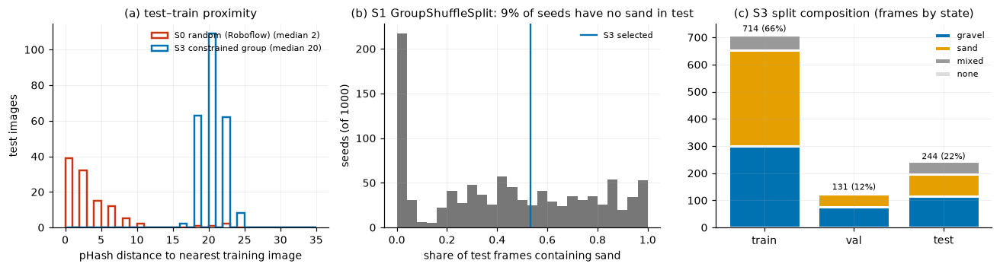

In [39]:
df_res = pd.DataFrame(res)
save_table(df_res, "split_strategy_comparison")
show = df_res.set_index("strategy")[["train_frac", "val_frac", "test_frac", "val_js", "test_js", "val_sand_groups", "test_sand_groups",
                                     "groups_spanning_splits", "near_dup_pairs_cross_split", "test_to_train_nn_median"]]
display(show.round(3).T)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for name, a, col in [("S0 random (Roboflow)", assign_S0, "#CC3311"), ("S3 constrained group", assign_S3, "#0072B2")]:
    te, tr = np.where(a == "test")[0], np.where(a == "train")[0]
    nn = D[np.ix_(te, tr)].min(axis=1)
    axes[0].hist(nn, bins=np.arange(0, 36), histtype="step", lw=1.6, color=col, label=f"{name} (median {np.median(nn):.0f})")
axes[0].set_xlabel("pHash distance to nearest training image"); axes[0].set_ylabel("test images")
axes[0].legend(frameon=False, fontsize=7); axes[0].set_title("(a) test–train proximity")
axes[1].hist(df_s1.test_sand_share, bins=np.linspace(0, 1, 26), color="#777777")
axes[1].axvline(np.isin(st_vals[assign_S3 == "test"], ["sand", "mixed"]).mean(), color="#0072B2", lw=1.5, label="S3 selected")
axes[1].set_xlabel("share of test frames containing sand"); axes[1].set_ylabel("seeds (of 1000)")
axes[1].set_title(f"(b) S1 GroupShuffleSplit: {(~df_s1.test_has_sand).mean()*100:.0f}% of seeds have no sand in test")
axes[1].legend(frameon=False, fontsize=7)
comp = pd.crosstab(pd.Series(assign_S3, name="split"), df_img.state).reindex(["train", "val", "test"])[[s for s in STATES if s in df_img.state.unique()]]
bottom = np.zeros(3)
for s in comp.columns:
    bars = axes[2].bar(comp.index, comp[s], bottom=bottom, color=CLASS_COLORS.get(s, "#999999" if s == "mixed" else "#DDDDDD"),
                       edgecolor="white", lw=2, label=s)
    bottom += comp[s].values
for k, v in enumerate(bottom):
    axes[2].text(k, v + 8, f"{int(v)} ({v/N*100:.0f}%)", ha="center", fontsize=7)
axes[2].legend(frameon=False, fontsize=7); axes[2].set_title("(c) S3 split composition (frames by state)")
fig.tight_layout(); savefig(fig, "fig15_split_strategies"); plt.show()

### 12.2 Grouped cross-validation ภายในชุดพัฒนา

**Method** ใช้ train ∪ val ของ S3 สร้าง fold แบบกลุ่ม โดยให้กลุ่มที่ใหญ่ที่สุด (2be0c9f6) อยู่ใน train ทุก fold และให้ val ของทุก fold มีเฟรม gravel และ sand อย่างน้อยอย่างละ 20 เฟรม จำนวน fold เท่ากับจำนวนกลุ่มที่มีเฟรม sand อย่างน้อย 20 เฟรมที่เหลือในชุดพัฒนา (สูงสุด 4) แผนเดิมกำหนด 4 fold ถ้าจำนวนจริงต่างจากนี้จะบันทึกใน `RESEARCH_PLAN.md` หัวข้อ 15

**Rationale** การยืนยันผลขั้นสุดท้ายใน Notebook 03 ต้องการค่าประมาณที่ไม่ขึ้นกับ val ชุดเดียว (Roberts et al., 2017)

**Limitation** fold ที่ได้มีขนาดไม่เท่ากัน เพราะกลุ่มมีขนาดต่างกัน

In [40]:
dev_groups = [g for g in grp_info.index if gs_best[g] != "test"]
sand_dev = [g for g in dev_groups if g not in PIN_TRAIN and grp_info.loc[g, "sand_frames"] >= 20]
N_FOLDS = min(4, len(sand_dev))
CONFIG["n_cv_folds"] = N_FOLDS
print(f"dev groups with >=20 sand frames (excluding pinned train): {[g[:8] for g in sand_dev]} -> folds = {N_FOLDS}")

# กำหนดกลุ่ม sand หนึ่งกลุ่มต่อ fold ก่อน แล้วค้นหาการวางกลุ่มที่เหลือให้ขนาด fold ใกล้กันและทุก fold มี gravel
rng = np.random.default_rng(SEED)
best_cv, best_score = None, np.inf
sand_sorted = sorted(sand_dev, key=lambda g: -n_img[g])
others = [g for g in dev_groups if g not in sand_dev and g not in PIN_TRAIN]
target = sum(n_img[g] for g in sand_dev + others) / N_FOLDS
for t in range(20_000):
    fold_of = {g: k for k, g in enumerate(rng.permutation(sand_sorted)[:N_FOLDS])}
    for g in sand_sorted[N_FOLDS:]:
        fold_of[g] = int(rng.integers(N_FOLDS))
    for g in others:
        fold_of[g] = int(rng.integers(N_FOLDS))
    sizes = np.zeros(N_FOLDS); grav = np.zeros(N_FOLDS); sand = np.zeros(N_FOLDS)
    for g, k in fold_of.items():
        sizes[k] += n_img[g]; grav[k] += grp_info.loc[g, "gravel_frames"]; sand[k] += grp_info.loc[g, "sand_frames"]
    if (grav < 20).any() or (sand < 20).any():
        continue
    sc = np.abs(sizes - target).sum()
    if sc < best_score:
        best_score, best_cv = sc, dict(fold_of)
assert best_cv is not None, "no feasible CV assignment"
fold_img = np.array([best_cv.get(g, -1) for g in G])          # -1 = pinned train หรือ test
cv_tab = pd.DataFrame([dict(fold=k, val_images=int((fold_img == k).sum()),
                            val_groups=",".join(sorted(g[:8] for g, f in best_cv.items() if f == k)),
                            **{f"val_{s}": int(((fold_img == k) & (st_vals == s)).sum()) for s in ["gravel", "sand", "mixed"]})
                       for k in range(N_FOLDS)])
save_table(cv_tab, "cv_folds")
display(cv_tab)

dev groups with >=20 sand frames (excluding pinned train): ['1991989f', '6459c886', 'bbf45eda'] -> folds = 3


saved table: outputs/01_eda/df6d6fdc28/tables/cv_folds.csv  (3 rows)


,fold,val_images,val_groups,val_gravel,val_sand,val_mixed
0,0,176,"1991989f,5079fbab,6f40fbbd,b029e315,e9eebbd1",119,0,57
1,1,176,"6459c886,68935cd9,9056e676,96ecd4fe,c6f16e4e,d...",122,50,0
2,2,177,"04802d75,07451999,2f4b2f2f,51647d0e,bbf45eda,f...",134,36,7


## 13. การเขียน manifest และชุดข้อมูลพัฒนา

**Implementation**

- `manifests/images_<hash>.csv`: ภาพทุกภาพพร้อม SHA-256, กลุ่มเดิม, กลุ่มที่รวมแล้ว, split, fold และสถานะ
- `manifests/dataset_versions.json`: ประวัติเวอร์ชันของชุดข้อมูล (bronze → silver → dev)
- `data/dev_<hash>/`: โครงสร้าง YOLO (`train/`, `val/`, `test/`; ภาพเป็น symbolic link ไปยัง Silver และ label เป็นสำเนา) พร้อม `data.yaml`
- `data/dev_<hash>/annotations/{train,val,test}_coco.json`: GT แบบ COCO (category_id 1 = gravel, 2 = sand; instance ที่เป็น ignore ใช้ `iscrowd=1`)
- `data/dev_<hash>/cv/`: รายการภาพของแต่ละ fold และ `data_fold<k>.yaml`

ชุด test ถูกบันทึกพร้อม hash และ Notebook 02–03 ต้องไม่โหลดจนถึงขั้นประเมินสุดท้าย

In [41]:
df_img["split"] = assign_S3
df_img["cv_fold"] = fold_img
split_key = hashlib.sha256((SILVER_HASH + "|" + "|".join(f"{n}:{s}:{f}" for n, s, f in
                            zip(df_img.silver_name, df_img.split, df_img.cv_fold))).encode()).hexdigest()[:12]
DEV_DIR = ROOT / "data" / f"dev_{split_key}"
CONFIG["dev_hash"] = split_key

man = df_img[["image_id", "silver_name", "file", "rf_split", "sha256", "width", "height", "group", "group_merged",
              "frame", "is_video", "state", "split", "cv_fold"]].copy()
man_path = ROOT / "manifests" / f"images_{split_key}.csv"
man.to_csv(man_path, index=False)
print("manifest:", man_path.relative_to(ROOT), len(man))

def coco_gt(split_name):
    sub = df_img[df_img.split == split_name]
    images, anns = [], []
    aid = 1
    for r in sub.itertuples():
        images.append(dict(id=int(r.image_id), file_name=r.silver_name, width=int(r.width), height=int(r.height)))
        for g in df_silver[(df_silver.image_id == r.image_id) & (df_silver.role != "dropped")].itertuples():
            xy = np.asarray(g.geom.exterior.coords)[:-1]
            minx, miny, maxx, maxy = g.geom.bounds
            anns.append(dict(id=aid, image_id=int(r.image_id), category_id=int(g.cls) + 1,
                             segmentation=[xy.ravel().round(2).tolist()], area=float(g.geom.area),
                             bbox=[float(minx), float(miny), float(maxx - minx), float(maxy - miny)],
                             iscrowd=int(g.role == "train_only_ignore_eval")))
            aid += 1
    return dict(info=dict(description=f"dev {split_key} {split_name}", silver=SILVER_HASH),
                images=images, annotations=anns,
                categories=[dict(id=1, name="gravel"), dict(id=2, name="sand")])

if (DEV_DIR / "data.yaml").exists():
    print(f"dev dataset already exists, not rewritten: {DEV_DIR.relative_to(ROOT)}")
else:
    for s in ("train", "val", "test"):
        (DEV_DIR / s / "images").mkdir(parents=True, exist_ok=True); (DEV_DIR / s / "labels").mkdir(parents=True, exist_ok=True)
    for r in df_img.itertuples():
        dst = DEV_DIR / r.split / "images" / r.silver_name
        if not dst.exists():
            os.symlink(SILVER_DIR / "images" / r.silver_name, dst)
        lbl = Path(r.silver_name).stem + ".txt"
        (DEV_DIR / r.split / "labels" / lbl).write_text((SILVER_DIR / "labels" / lbl).read_text())
    (DEV_DIR / "annotations").mkdir(exist_ok=True)
    for s in ("train", "val", "test"):
        (DEV_DIR / "annotations" / f"{s}_coco.json").write_text(json.dumps(coco_gt(s)))
    (DEV_DIR / "data.yaml").write_text(f"path: {DEV_DIR}\ntrain: train/images\nval: val/images\ntest: test/images\n"
                                       f"nc: 2\nnames: ['gravel', 'sand']\n")
    (DEV_DIR / "cv").mkdir(exist_ok=True)
    for k in range(N_FOLDS):
        tr = [str(DEV_DIR / r.split / "images" / r.silver_name) for r in df_img.itertuples() if r.split != "test" and r.cv_fold != k]
        va = [str(DEV_DIR / r.split / "images" / r.silver_name) for r in df_img.itertuples() if r.split != "test" and r.cv_fold == k]
        (DEV_DIR / "cv" / f"fold{k}_train.txt").write_text("\n".join(tr) + "\n")
        (DEV_DIR / "cv" / f"fold{k}_val.txt").write_text("\n".join(va) + "\n")
        (DEV_DIR / "cv" / f"data_fold{k}.yaml").write_text(f"train: {DEV_DIR}/cv/fold{k}_train.txt\nval: {DEV_DIR}/cv/fold{k}_val.txt\n"
                                                         f"nc: 2\nnames: ['gravel', 'sand']\n")
    (DEV_DIR / "split_meta.json").write_text(json.dumps(dict(
        dev_hash=split_key, silver_hash=SILVER_HASH, strategy="S3 constrained group split", seed=SEED,
        pinned_test=[g[:8] for g in PIN_TEST], pinned_train=[g[:8] for g in PIN_TRAIN],
        val_groups=[g[:8] for g in best.val_groups], test_groups=[g[:8] for g in best.test_groups],
        counts={s: int((df_img.split == s).sum()) for s in ("train", "val", "test")},
        test_sha256=sorted(df_img.sha256[df_img.split == "test"].tolist()),
        n_cv_folds=N_FOLDS, created=time.strftime("%Y-%m-%dT%H:%M:%S%z")), indent=2))
    print(f"dev dataset written: {DEV_DIR.relative_to(ROOT)}")

ver_path = ROOT / "manifests" / "dataset_versions.json"
versions = json.loads(ver_path.read_text()) if ver_path.exists() else []
entry = dict(stage="dev", dev_hash=split_key, silver_hash=SILVER_HASH, bronze=str(BRONZE),
             bronze_roboflow="aggregate_rock-and-sand v5", notebook_run=RUN_ID, silver_params=P,
             near_dup_threshold=D_ND, n_cv_folds=N_FOLDS, manifest=str(man_path.relative_to(ROOT)))
if not any(v.get("dev_hash") == split_key for v in versions):
    versions.append({**entry, "recorded": time.strftime("%Y-%m-%dT%H:%M:%S%z")})
    ver_path.write_text(json.dumps(versions, indent=2))
print(json.dumps(entry, indent=2))

manifest: manifests/images_19659e679798.csv 1089
dev dataset already exists, not rewritten: data/dev_19659e679798
{
  "stage": "dev",
  "dev_hash": "19659e679798",
  "silver_hash": "0997f3096843",
  "bronze": "/home/supawich/Desktop/Aggregate_Project/implement/data/bronze",
  "bronze_roboflow": "aggregate_rock-and-sand v5",
  "notebook_run": "df6d6fdc28",
  "silver_params": {
    "eps_frac": 0.0025,
    "tau_iomin": 0.7,
    "dup_merge": "union",
    "a_floor_px640": 64.0,
    "a_min_frac": 0.001,
    "r_max_eval": Infinity
  },
  "near_dup_threshold": 8,
  "n_cv_folds": 3,
  "manifest": "manifests/images_19659e679798.csv"
}


## 14. ด่านตรวจ G1

ตรวจเงื่อนไขทั้งหมดก่อนส่งต่อชุดข้อมูลให้ Notebook 02 ถ้าข้อใดไม่ผ่าน cell จะหยุดด้วย `AssertionError`

In [42]:
from pycocotools.coco import COCO
import contextlib, io
gate = {}
sp = pd.Series(assign_S3)
gate["no group spans two splits"] = int(sp.groupby(G).nunique().max()) == 1
gate["no near-duplicate pair (d<=D_ND) across splits"] = split_metrics(assign_S3, "x")["near_dup_pairs_cross_split"] == 0
for s in ("train", "val", "test"):
    stt = set(df_img.state[df_img.split == s])
    gate[f"{s} contains gravel and sand frames"] = bool(stt & {"gravel", "mixed"}) and bool(stt & {"sand", "mixed"})
gate["thesis-video groups in test"] = all(gs_best[g] == "test" for g in PIN_TEST)
for s in ("train", "val", "test"):
    n_files = len(list((DEV_DIR / s / "images").iterdir()))
    n_lbl = len(list((DEV_DIR / s / "labels").glob("*.txt")))
    gate[f"{s}: images == labels == manifest"] = n_files == n_lbl == int((df_img.split == s).sum())
    with contextlib.redirect_stdout(io.StringIO()):
        coco = COCO(str(DEV_DIR / "annotations" / f"{s}_coco.json"))
    gate[f"{s}: COCO GT loads ({len(coco.imgs)} imgs, {len(coco.anns)} anns)"] = len(coco.imgs) == int((df_img.split == s).sum())
meta = json.loads((DEV_DIR / "split_meta.json").read_text())
gate["test sha256 list matches manifest"] = meta["test_sha256"] == sorted(df_img.sha256[df_img.split == "test"])
for k in range(N_FOLDS):
    va = set(df_img.group_merged[(df_img.cv_fold == k)])
    tr = set(df_img.group_merged[(df_img.split != "test") & (df_img.cv_fold != k)])
    gate[f"fold {k}: no group overlap between train and val"] = not (va & tr)
for k, v in gate.items():
    print(("PASS " if v else "FAIL ") + k)
(OUT / "gate_G1.json").write_text(json.dumps({k: bool(v) for k, v in gate.items()}, indent=2))
assert all(gate.values()), "Gate G1 failed"
print("\nGate G1 passed. dev dataset:", DEV_DIR.relative_to(ROOT))

PASS no group spans two splits
PASS no near-duplicate pair (d<=D_ND) across splits
PASS train contains gravel and sand frames
PASS val contains gravel and sand frames
PASS test contains gravel and sand frames
PASS thesis-video groups in test
PASS train: images == labels == manifest
PASS train: COCO GT loads (714 imgs, 3001 anns)
PASS val: images == labels == manifest
PASS val: COCO GT loads (131 imgs, 429 anns)
PASS test: images == labels == manifest
PASS test: COCO GT loads (244 imgs, 755 anns)
PASS test sha256 list matches manifest
PASS fold 0: no group overlap between train and val
PASS fold 1: no group overlap between train and val
PASS fold 2: no group overlap between train and val

Gate G1 passed. dev dataset: data/dev_19659e679798


## 14.1 ความทนทานของการแบ่งต่อเกณฑ์ภาพเกือบซ้ำ

**Method** (1) นับคู่ภาพข้าม split ของการแบ่งที่เลือกที่เกณฑ์ pHash เข้มขึ้น (d ≤ 10 และ d ≤ 12) (2) ตรวจด้วยวิธีที่สองที่ไม่ขึ้นกับ pHash: embedding จากแบบจำลอง YOLO26n-seg ที่ pretrain บน COCO (`YOLO.embed`, ค่าเฉลี่ยของ feature map ชั้นท้ายของ backbone) แล้วเปรียบเทียบ cosine similarity ของภาพ val/test กับภาพ train ที่ใกล้ที่สุด กับ similarity ระหว่างเฟรมในวิดีโอเดียวกัน

**Rationale** ถ้าการแบ่งยังไม่มีคู่ภาพใกล้กันผิดปกติเมื่อใช้เกณฑ์ที่เข้มกว่า และ similarity ข้าม split ต่ำกว่าภายในวิดีโออย่างชัดเจน จะลดความเป็นไปได้ที่ยังมีเหตุการณ์ซ้ำที่ตรวจไม่พบ

**Limitation** embedding ของแบบจำลองที่ฝึกบน COCO วัดความคล้ายของฉากโดยรวม ภาพจากจุดติดตั้งกล้องเดียวกันจึงมี similarity สูงได้แม้เป็นคนละเหตุการณ์ ผลจึงต้องตรวจด้วยตาร่วมด้วย

In [43]:
for thr in (D_ND, 10, 12):
    m = (pair.d.values <= thr) & (assign_S3[pair.i.values] != assign_S3[pair.j.values])
    sub = pair[m]
    gp = pd.Series([f"{G[a][:8]}({assign_S3[a]})~{G[b][:8]}({assign_S3[b]})" for a, b in zip(sub.i, sub.j)]).value_counts()
    print(f"d <= {thr}: cross-split pairs = {int(m.sum())}", dict(gp.head(6)))

d <= 8: cross-split pairs = 0 {}
d <= 10: cross-split pairs = 4 {'2be0c9f6(train)~fa45e6fb(val)': np.int64(2), 'fa45e6fb(val)~2be0c9f6(train)': np.int64(2)}
d <= 12: cross-split pairs = 510 {'2be0c9f6(train)~fa45e6fb(val)': np.int64(390), 'fa45e6fb(val)~2be0c9f6(train)': np.int64(115), '6f40fbbd(train)~fa45e6fb(val)': np.int64(3), 'b029e315(train)~07451999(val)': np.int64(2)}


embeddings (1089, 256) in 4.0s


saved figure: outputs/01_eda/df6d6fdc28/figures/fig16_embedding_similarity.png|pdf


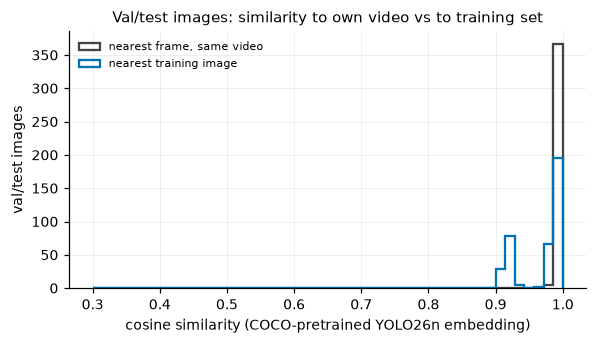

split                   test      val
sim_train     count  244.000  131.000
              mean     0.954    0.990
              std      0.034    0.003
              min      0.904    0.979
              50%      0.978    0.990
              95%      0.990    0.993
              max      0.993    0.994
sim_own_group count  240.000  131.000
              mean     0.997    0.997
              std      0.003    0.003
              min      0.985    0.976
              50%      0.997    0.998
              95%      0.999    0.999
              max      0.999    0.999


saved figure: outputs/01_eda/df6d6fdc28/figures/fig17_embedding_closest_pairs.png|pdf


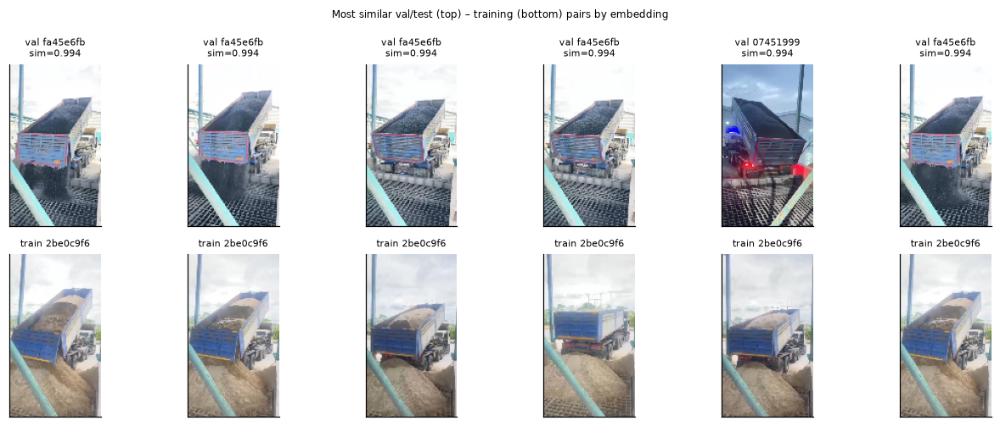

saved table: outputs/01_eda/df6d6fdc28/tables/split_embedding_similarity.csv  (375 rows)


In [44]:
import torch
from ultralytics import YOLO
W_BASE = ROOT / "weights" / "yolo26n-seg.pt"
emb_model = YOLO(str(W_BASE))
t0 = time.time()
E = []
for k in range(0, len(df_img), 32):
    batch = df_img.img_path.iloc[k:k + 32].tolist()
    E.extend([e.float().cpu().numpy().ravel() for e in emb_model.embed(batch, imgsz=640, verbose=False)])
E = np.stack(E); E /= np.linalg.norm(E, axis=1, keepdims=True)
S = E @ E.T; np.fill_diagonal(S, -1)
print(f"embeddings {E.shape} in {time.time()-t0:.1f}s")
tr_idx = np.where(assign_S3 == "train")[0]
rows = []
for s in ("val", "test"):
    for i in np.where(assign_S3 == s)[0]:
        j = tr_idx[np.argmax(S[i, tr_idx])]
        same = np.where((G == G[i]) & (np.arange(len(G)) != i))[0]
        rows.append(dict(split=s, i=i, nn_train=j, sim_train=S[i, j], sim_own_group=S[i, same].max() if len(same) else np.nan))
df_emb = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.hist(df_emb.sim_own_group.dropna(), bins=np.linspace(0.3, 1, 50), histtype="step", lw=1.5, color="#444444", label="nearest frame, same video")
ax.hist(df_emb.sim_train, bins=np.linspace(0.3, 1, 50), histtype="step", lw=1.5, color="#0072B2", label="nearest training image")
ax.set_xlabel("cosine similarity (COCO-pretrained YOLO26n embedding)"); ax.set_ylabel("val/test images"); ax.legend(frameon=False, fontsize=7)
ax.set_title("Val/test images: similarity to own video vs to training set")
fig.tight_layout(); savefig(fig, "fig16_embedding_similarity"); plt.show()
print(df_emb.groupby("split")[["sim_train", "sim_own_group"]].describe(percentiles=[.5, .95]).round(3).T)
top = df_emb.nlargest(6, "sim_train")
fig, axes = plt.subplots(2, 6, figsize=(12, 4.6))
for c, r in enumerate(top.itertuples()):
    for rr, idx in enumerate((r.i, r.nn_train)):
        ax = axes[rr, c]; ax.imshow(thumb(df_img.img_path[idx], 160)); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(f"{assign_S3[idx]} {G[idx][:8]}" + (f"\nsim={r.sim_train:.3f}" if rr == 0 else ""), fontsize=7)
fig.suptitle("Most similar val/test (top) – training (bottom) pairs by embedding", fontsize=8)
fig.tight_layout(); savefig(fig, "fig17_embedding_closest_pairs"); plt.show()
save_table(df_emb, "split_embedding_similarity")

In [45]:
# สรุปตัวเลขสำคัญสำหรับรายงาน และบันทึก config ทั้งหมดของ notebook
summary = dict(
    run_id=RUN_ID, silver_hash=SILVER_HASH, dev_hash=split_key,
    bronze_images=len(df_img), bronze_instances=len(df_inst),
    annotation_issues=issue_summary.set_index("issue")["count"].to_dict() if len(issue_summary) else {},
    groups_raw=int(df_img.group.nunique()), groups_merged=int(df_img.group_merged.nunique()),
    silver_roles=df_silver.role.value_counts().to_dict(),
    split_counts={s: int((df_img.split == s).sum()) for s in ("train", "val", "test")},
    split_state_counts=pd.crosstab(df_img.split, df_img.state).to_dict(orient="index"),
    roboflow_split_leakage=dict(groups_spanning=int(res[0]["groups_spanning_splits"]),
                                near_dup_pairs_cross_split=int(res[0]["near_dup_pairs_cross_split"])),
    cramers_v=None,
)
summary["cramers_v"] = dict(zip(pd.read_csv(TAB / "confounding_cramers_v.csv").variable, pd.read_csv(TAB / "confounding_cramers_v.csv").cramers_v.round(3)))
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
cfg_path = OUT / "config.json"
if cfg_path.exists() and json.loads(cfg_path.read_text()) != json.loads(json.dumps(CONFIG, default=str)):
    raise RuntimeError(f"{cfg_path} มี config ต่างจากการรันนี้ — เปลี่ยนค่าใน CONFIG ตอนต้นเพื่อให้ได้ RUN_ID ใหม่ แทนการเขียนทับ")
cfg_path.write_text(json.dumps(CONFIG, indent=2, default=str))
(ROOT / "outputs" / "01_eda" / "LATEST").write_text(RUN_ID + "\n")
print(json.dumps(summary, indent=2, default=str))

{
  "run_id": "df6d6fdc28",
  "silver_hash": "0997f3096843",
  "dev_hash": "19659e679798",
  "bronze_images": 1089,
  "bronze_instances": 6023,
  "annotation_issues": {
    "duplicate_line": 1,
    "invalid_geometry": 253,
    "lt3_vertices": 55,
    "zero_area": 154
  },
  "groups_raw": 32,
  "groups_merged": 27,
  "silver_roles": {
    "train_and_eval": 3861,
    "train_only_ignore_eval": 324,
    "dropped": 190
  },
  "split_counts": {
    "train": 714,
    "val": 131,
    "test": 244
  },
  "split_state_counts": {
    "test": {
      "gravel": 114,
      "mixed": 48,
      "none": 0,
      "sand": 82
    },
    "train": {
      "gravel": 300,
      "mixed": 57,
      "none": 5,
      "sand": 352
    },
    "val": {
      "gravel": 75,
      "mixed": 7,
      "none": 0,
      "sand": 49
    }
  },
  "roboflow_split_leakage": {
    "groups_spanning": 14,
    "near_dup_pairs_cross_split": 6948
  },
  "cramers_v": {
    "source group": 0.981,
    "resolution": 0.628
  }
}


## 15. สรุปผลของ Notebook 01

### 15.1 คุณภาพของชุดข้อมูล

- ชุด bronze มี 1,089 ภาพ (JPEG/RGB ทั้งหมด) และ 6,023 instance (gravel 2,876 / sand 3,147) ทุกภาพมีไฟล์ label คู่กัน และไม่มีไฟล์ภาพซ้ำแท้ (SHA-256)
- ปัญหาของ annotation ได้แก่ geometry ตัดกันเอง 253 ชิ้น, พื้นที่ศูนย์ 154 ชิ้น, จุดยอดน้อยกว่า 3 จุด 55 ชิ้น และบรรทัดซ้ำ 1 บรรทัด
- คู่ instance คลาสเดียวกันที่ซ้อนทับกันมี 2,086 คู่ (median IoMin 0.99) ส่วนใหญ่เป็นการวาด polygon ทับกันระหว่างกองวัสดุทั้งกองกับส่วนย่อย ไม่พบการซ้อนทับระหว่างคลาส
- instance ของ gravel มีขนาดกระจายกว้างกว่า sand ร้อยละ 25 ของ instance gravel มีพื้นที่น้อยกว่า 0.094% ของภาพ ส่วนใหญ่เป็นเศษหินบนตะแกรง

### 15.2 โครงสร้างกลุ่มและตัวแปรกวน

- หน่วยกลุ่มเริ่มต้นมี 32 หน่วย (วิดีโอ 18 กลุ่มและภาพนิ่ง 14 ภาพ) การตรวจภาพเกือบซ้ำ (pHash, d ≤ 8) พบวิดีโอสองคู่ที่เป็นเหตุการณ์เดียวกันแต่บันทึกเป็นคนละไฟล์ (0f964fdb กับ 5d81688a; 8f435cb5 กับ b029e315) และภาพนิ่ง "download" สามภาพเป็นเฟรมจากวิดีโอ 2be0c9f6 และ 07451999 หลังรวมเหลือ 27 กลุ่ม
- เกณฑ์ที่เข้มขึ้น (d ≤ 10) พบคู่ภาพข้าม split เพิ่มเพียง 4 คู่ ระหว่าง 2be0c9f6 (sand, train) กับ fa45e6fb (gravel, val) ซึ่งตรวจด้วยตาแล้วเป็นจุดติดตั้งกล้องเดียวกันแต่ต่างเหตุการณ์และต่างวัสดุ
- คลาสผูกกับแหล่งที่มาอย่างมาก (Cramér's V = 0.98) และผูกกับความละเอียดภาพในระดับสูง (V = 0.63) แบบจำลองจึงมีโอกาสใช้ลักษณะของฉากเป็นทางลัด การประเมินต้องใช้กลุ่มที่ไม่เคยเห็นเท่านั้น และ Notebook 03 จะทดสอบ shortcut โดยตรง

### 15.3 การแบ่งชุดข้อมูล (RQ1)

| กลยุทธ์ | ข้อดี | ข้อเสียที่พบในข้อมูลนี้ |
|---|---|---|
| S0 สุ่มระดับภาพ (Roboflow) | การกระจายคลาสใกล้เคียงกันทุก split | 14 หน่วยกลุ่มอยู่ข้าม split และมีคู่ภาพเกือบซ้ำข้าม split 6,948 คู่; ภาพทดสอบห่างจากภาพฝึกที่ใกล้ที่สุดเพียง median d = 2 |
| S1 GroupShuffleSplit | ไม่มี leakage | ขนาด test แปรผัน 4.8–42.6% (เปอร์เซ็นไทล์ 5–95) และ 9.0% ของ seed ได้ test ที่ไม่มี sand |
| S2 StratifiedGroupKFold | ไม่มี leakage | stratification ทำไม่ได้เพราะมีกลุ่มขนาดใหญ่จำนวนน้อย ขนาดของ fold ต่างกันมาก สอดคล้องกับข้อจำกัดที่ระบุในเอกสาร scikit-learn |
| **S3 แบ่งระดับกลุ่มภายใต้เงื่อนไข (เลือกใช้)** | ไม่มี leakage, ควบคุมองค์ประกอบของคลาสได้, ภาพทดสอบห่างจากภาพฝึก median d = 20 | เงื่อนไขกำหนดโดยผู้วิจัย และจำนวนการแบ่งที่เป็นไปได้มีจำกัด |

การแบ่งที่เลือก: train 714 ภาพ (66%), val 131 ภาพ (12%), test 244 ภาพ (22%)

- test: กลุ่ม 0a48349e (sand), 0f964fdb+5d81688a (gravel) และ 4a7f29af (mixed) รวมกับภาพนิ่งบางภาพ ครอบคลุมคลิปใน `thesis_videos` สองคลิป
- val: 6459c886 (sand), 07451999 และ fa45e6fb (gravel)
- grouped CV ภายในชุดพัฒนา 3 fold (จำนวน fold ถูกจำกัดด้วยกลุ่มที่มีเฟรม sand อย่างน้อย 20 เฟรม)

**ข้อเสนอ:** ใช้ S3 เป็นการแบ่งหลัก ใช้ val สำหรับคัดกรองและเลือก hyperparameter ใช้ grouped CV 3 fold ยืนยันการตั้งค่าสุดท้ายเทียบกับ baseline และเปิดผลบน test เพียงครั้งเดียวใน Notebook 03

### 15.4 ชุดข้อมูล Silver

จาก 6,023 instance ใน bronze ได้ 4,375 instance หลังซ่อม geometry และรวม annotation ซ้ำ

| บทบาท | จำนวน |
|---|---:|
| GT ปกติ (ใช้ฝึกและประเมิน) | 3,861 |
| ใช้ฝึก แต่เป็น ignore region ในชุดประเมิน (พื้นที่ < 0.1%) | 324 |
| ตัดออก (เล็กกว่าหนึ่ง cell ของ P3) | 190 |

การตรวจตัวอย่าง 120 ชิ้นโดยผู้ช่วยวิจัย (หัวข้อ 10.1) ไม่พบการตัดสินผิดในชั้น merged, dropped และ unchanged (0/30 ในแต่ละชั้น; ขอบบนของ 95% CI ≈ 11%) และมี 5 ชิ้นที่ไม่แน่ใจ ในชั้น ignore พบ 7/30 ชิ้นที่ไม่ควร ignore ทั้งหมดเป็นแถบหินบนตะแกรงที่ถูกจับโดยกฎ aspect เท่านั้น จึงตัดกฎ aspect ออกจากกฎสุดท้าย และพบกองหินที่ไม่ได้ annotate หนึ่งกรณี (UN29) ซึ่งบ่งชี้ว่ามี label หายในชุดข้อมูลอยู่บ้าง

### 15.5 ข้อจำกัดที่ต้องนำไปใช้ใน Notebook ถัดไป

1. val มีขนาดเล็ก (131 ภาพ) และมีกลุ่ม sand ขนาดใหญ่เพียงกลุ่มเดียว (6459c886) ผลของ sand บน val จึงมีความแปรปรวนสูง การตัดสินใจขั้นสุดท้ายต้องใช้ grouped CV ประกอบ
2. sand ใน test มาจากวิดีโอ 0a48349e เป็นหลัก ซึ่งเป็นฉากที่มืดกว่าชุดอื่น (L\* เฉลี่ย 51 เทียบกับ median 70) ผล sand บน test จึงสะท้อนสภาพแสงน้อยด้วย ต้องรายงานแยกรายกลุ่มพร้อม cluster bootstrap และใช้ CV กับ holdout เป็นหลักฐานประกอบ
3. ชุดพัฒนามีภาพสถานะ `none` เพียง 5 ภาพ จึงประเมินสถานะนี้ไม่ได้จากชุดพัฒนา และไม่มีข้อมูลเพิ่มให้ใช้
4. group key และการรวมกลุ่มอาศัยชื่อไฟล์และ pHash ไม่มี metadata ของวันที่หรือสถานที่ถ่าย
5. กฎ Silver เป็น heuristic ที่ทำซ้ำได้ และการตรวจตัวอย่างทำโดยผู้ช่วยวิจัยเพียงรายเดียว ไม่ใช่ผู้ตรวจที่เป็นมนุษย์อิสระ